## Pontificia Universidad Javeriana

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSD1Tsz-TGSmWtmI0NCrivhX8pcljNrvDgMETaY1n7WAMQ_AwTbCAwjKIR0&s=10" alt="drawing" width="200"/>

# Procesamiento de Datos a Gran Escala

# PySpark con Modelos de Machine Learning

### Fecha: 18 de noviembre de 2026

### Autor: Lorenzo Ramirez Calderon (ID: 20550074)

### Docente: John Jairo Corredor

**Objetivos:**
- Hacer uso del entorno IDE Python cuaderno: servidor.
- Usar un dataset de Enfermedades Cardiovasculares
- Desplegar la metodologia CRISP_DM sobre Enfermedades Cardiovasculares
- Explorar las diferentes bibliotecas disponibles.
- Identificar la forma de instalacion de nuevas bibliotecas, sobre el kernel por defecto.
- Hacer documentacion extensiva sobre cada tarea/actividad
- Hacer analisis y conclusiones.


**Contexto**

Los derrames cerebrales constituyen una problemática de salud debido a sus consecuencias sobre la calidad de vida de los pacientes. La identificación de características demográficas, clínicas y relacionadas con los hábitos de vida que permitan reconocer pacientes con mayor riesgo representa una oportunidad para la aplicación de técnicas de aprendizaje automático.

El presente taller tiene como objetivo desarrollar y evaluar modelos de clasificación binaria mediante Apache Spark y su biblioteca de aprendizaje automático MLlib, utilizando un conjunto de datos compuesto por 5.109 pacientes. Finalmente, se realiza un análisis comparativo de los modelos mediante diferentes métricas de rendimiento, considerando la capacidad de identificar correctamente a los pacientes que han sufrido un derrame cerebral.

In [1]:
#Generic Libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

#Apache Spark Libraries
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')

#Apache Spark Libraries
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession, SQLContext, functions as F
from pyspark.sql.types import NumericType

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import LogisticRegression,DecisionTreeClassifier,RandomForestClassifier,GBTClassifier, MultilayerPerceptronClassifier

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipeline Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector

# Apache Spark 'Vector to Array'
from pyspark.ml.functions import vector_to_array

### Importacion librerias para graficar curvas ROC se usa sklearn solo para visualizar todo el entrenamiento es con MLLib
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)


#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split


#Garbage
import gc

In [2]:
### Bibliotecas Adicionales
# Biblioteca Estadistica/Inerencia/Probabilidad y pintar
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


In [3]:
### Instancia de Configuracion
configura = SparkConf().set("spark.ui.port","37015")
configura.setAppName("LorenzoTallerStroke")

### Sesion Spark
sparkRamirez =  SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkRamirez, sparkSession=sparkRamirez)

sparkContextoRamirez = sparkRamirez.sparkContext.getOrCreate()


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


In [4]:
sparkRamirez

In [5]:
# Se observa la carpeta CSV del datalake HADOOP
# La idea es usar el dataset desde el Hadoop para usarlo de manera remota
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /csv

Found 11 items
drwxr-xr-x   - sistemas supergroup          0 2026-10-23 13:39 /csv/BankMarketing
-rw-r--r--   2 sistemas supergroup     977501 2026-03-10 15:27 /csv/CustomerChurn.csv
-rw-r--r--   2 sistemas supergroup      40868 2025-07-07 15:41 /csv/Fortune500USCompanies.csv
drwxr-xr-x   - sistemas supergroup          0 2025-10-16 14:17 /csv/auxiliar
drwxr-xr-x   - sistemas supergroup          0 2026-11-12 12:16 /csv/calidadAgua
-rw-r--r--   2 sistemas supergroup      34635 2025-09-02 13:22 /csv/jugadores.csv
-rw-r--r--   2 sistemas supergroup    1082023 2025-09-02 13:22 /csv/resultados_futbol.csv
-rw-r--r--   2 sistemas supergroup     316971 2025-06-10 09:11 /csv/stroke_pyspark.csv
drwxr-xr-x   - sistemas supergroup          0 2025-06-18 15:36 /csv/taxi
drwxr-xr-x   - sistemas supergroup          0 2026-04-23 15:56 /csv/titanic
-rw-r--r--   2 sistemas supergroup      84199 2026-04-23 17:11 /csv/winequality-red.csv


In [6]:
# Se carga el dataset: spark_stroke.csv a la sesión actual de trabajo
url = "hdfs://10.195.34.34:9000/csv/stroke_pyspark.csv"

df00 = sparkRamirez.read.format("csv").option("header","true").load(url)

df00.show(5)

+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
|   id|gender|age|hypertension|heart_disease|ever_married|    work_type|Residence_type|avg_glucose_level| bmi| smoking_status|stroke|
+-----+------+---+------------+-------------+------------+-------------+--------------+-----------------+----+---------------+------+
| 9046|  Male| 67|           0|            1|         Yes|      Private|         Urban|           228.69|36.6|formerly smoked|     1|
|51676|Female| 61|           0|            0|         Yes|Self-employed|         Rural|           202.21| N/A|   never smoked|     1|
|31112|  Male| 80|           0|            1|         Yes|      Private|         Rural|           105.92|32.5|   never smoked|     1|
|60182|Female| 49|           0|            0|         Yes|      Private|         Urban|           171.23|34.4|         smokes|     1|
| 1665|Female| 79|           1|            0|         Yes|Self

## **1- Diagnostico y Tratamiento de Datos**
- Cambio de nombres de columnas (features)
- Tipos y coherencia de datos
- Identificacion y tratamiento de datos nulos/atipicos
- Estadistica de los datos
- Tratamiento de columnas categoricas

In [7]:
## Cambio de nombres de columnas (features)
df00.columns

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [8]:
nuevosNombres =['id', 'Genero', 'Edad',
                'HiperTension', 'EnfCardiaca', 'Casado',
                'TipoTrabajo', 'TipoResidencia', 'PromedioNivelGlucosa',
                'BMI', 'Fumador','Derrame'] 

### Se cambia por los nuevos nombres
df01 = df00

for antes,nuevo in zip(df00.columns, nuevosNombres):
    df01 = df01.withColumnRenamed(antes,nuevo)

df01.columns

['id',
 'Genero',
 'Edad',
 'HiperTension',
 'EnfCardiaca',
 'Casado',
 'TipoTrabajo',
 'TipoResidencia',
 'PromedioNivelGlucosa',
 'BMI',
 'Fumador',
 'Derrame']

#### Salida de la varible ID, en el estudio

La variable id tiene que ser removida del estudio puesto que esta no aporta a las caracterisitcas de cada paciente del dataset sino que
funciona solo como un identificador (llave primaria) de cada tupla dentro de este. Por lo anterior mantener esta tupla dentro del estudio generaria ruido en el posterior analisis y tecnicas de modelado. 

In [9]:
df01.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: string (nullable = true)
 |-- HiperTension: string (nullable = true)
 |-- EnfCardiaca: string (nullable = true)
 |-- Casado: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromedioNivelGlucosa: string (nullable = true)
 |-- BMI: string (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: string (nullable = true)



In [10]:
### Edad: double se cambia a entero
df02 = df01.withColumn("Edad", df01.Edad.cast("int"))

### Genero: String se cambia a String
df02 = df02.withColumn("Genero", df01.Genero.cast("string"))

### Hipertension: integer a entero
df02 = df02.withColumn("Hipertension", df01.HiperTension.cast("int"))

### EnfCardiaca: integer a entero
df02 = df02.withColumn("EnfCardiaca", df01.EnfCardiaca.cast("int"))

### PromedioNivelGlucosa: double a double
df02 = df02.withColumn("PromedioNivelGlucosa", df01.PromedioNivelGlucosa.cast("double"))

### BMI: string se castea a double
df02 = df02.withColumn("BMI", df01.BMI.cast("double"))

### Derrame: integer a entero
df02 = df02.withColumn("Derrame", df01.Derrame.cast("int"))

In [11]:
df02.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromedioNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [12]:
## Identificacion y tratamiento de datos nulos/atipicos

df02.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df02.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaca|Casado|TipoTrabajo|TipoResidencia|PromedioNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|                   0|201|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+



## Observacion y tratamiento de variables categoricas
- Genero
- Casado
- Tipo de trabajo
- Tipo de residencia
- Fumador

In [13]:
df02.printSchema()

root
 |-- id: string (nullable = true)
 |-- Genero: string (nullable = true)
 |-- Edad: integer (nullable = true)
 |-- Hipertension: integer (nullable = true)
 |-- EnfCardiaca: integer (nullable = true)
 |-- Casado: string (nullable = true)
 |-- TipoTrabajo: string (nullable = true)
 |-- TipoResidencia: string (nullable = true)
 |-- PromedioNivelGlucosa: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Fumador: string (nullable = true)
 |-- Derrame: integer (nullable = true)



In [14]:
# Generos en el dataset
df02.groupby(['Genero']).count().show()

[Stage 5:>                                                          (0 + 1) / 1]

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
| Other|    1|
|  Male| 2115|
+------+-----+



### Se retira other puesto que es un registro unico el cual no puede ser identificado entre Male o Female

In [15]:
### Se decarta other

df02 = df02.where("Genero <> 'Other'")
df02.groupby(['Genero']).count().show()

+------+-----+
|Genero|count|
+------+-----+
|Female| 2994|
|  Male| 2115|
+------+-----+



In [16]:
### Casado
df02.groupby(['Casado']).count().show()

+------+-----+
|Casado|count|
+------+-----+
|    No| 1756|
|   Yes| 3353|
+------+-----+



In [17]:
### Tipo de trabajo
df02.groupby(['TipoTrabajo']).count().show()

+-------------+-----+
|  TipoTrabajo|count|
+-------------+-----+
| Never_worked|   22|
|Self-employed|  819|
|      Private| 2924|
|     children|  687|
|     Govt_job|  657|
+-------------+-----+



In [18]:
### Residencia
df02.groupby(['TipoResidencia']).count().show()

+--------------+-----+
|TipoResidencia|count|
+--------------+-----+
|         Urban| 2596|
|         Rural| 2513|
+--------------+-----+



In [19]:
### Fumador
df02.groupby(['Fumador']).count().show()

+---------------+-----+
|        Fumador|count|
+---------------+-----+
|         smokes|  789|
|        Unknown| 1544|
|   never smoked| 1892|
|formerly smoked|  884|
+---------------+-----+



### Variable IMC : Indice de masa corporal


In [20]:
nulosBMI = (201/df02.count())*100
print(f"El porcentaje de nulos es = {nulosBMI}%")

El porcentaje de nulos es = 3.9342337052260716%



<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis</strong>

<p>
Se identificaron 201 valores faltantes en la variable BMI, equivalentes aproximadamente al 3,93 % de los 5.109 registros. Para conservar el tamaño de la muestra, se decidió reemplazar estos valores por promedios calculados según el género y el rango de edad de los individuos. 
</p>

</div>

In [21]:
## Para el 4% de datos de BMI, se ajusta para no eliminarlos
# Se saca el promedio de BMI para cambiarlos.
# El promedio se hara por edades y por genero.
# La estratificacion se hara por decadas

In [22]:
#Promedio de BMI por female y cada 10 años

avg10F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") <=10)).select(F.mean(F.col("BMI"))).collect()
avg20F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >10)& (F.col("Edad") <=20)).select(F.mean(F.col("BMI"))).collect()
avg30F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >20)& (F.col("Edad") <=30)).select(F.mean(F.col("BMI"))).collect()
avg40F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >30)& (F.col("Edad") <=40)).select(F.mean(F.col("BMI"))).collect()
avg50F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >40)& (F.col("Edad") <=50)).select(F.mean(F.col("BMI"))).collect()
avg60F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >50)& (F.col("Edad") <=60)).select(F.mean(F.col("BMI"))).collect()
avg70F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >60)& (F.col("Edad") <=70)).select(F.mean(F.col("BMI"))).collect()
avg80F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >70)& (F.col("Edad") <=80)).select(F.mean(F.col("BMI"))).collect()
avg90F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >80)& (F.col("Edad") <=90)).select(F.mean(F.col("BMI"))).collect()
avg100F = df02.where((F.col("Genero")==F.lit("Female"))& (F.col("Edad") >90)).select(F.mean(F.col("BMI"))).collect()



In [23]:
## Se imprime los promedios BMI femeninos

print(f"Promedio de 10 años femenino = {round(avg10F[0][0],2)} BMI")
print(f"Promedio de 20 años femenino = {round(avg20F[0][0],2)} BMI")
print(f"Promedio de 30 años femenino = {round(avg30F[0][0],2)} BMI")
print(f"Promedio de 40 años femenino = {round(avg40F[0][0],2)} BMI")
print(f"Promedio de 50 años femenino = {round(avg50F[0][0],2)} BMI")
print(f"Promedio de 60 años femenino = {round(avg60F[0][0],2)} BMI")
print(f"Promedio de 70 años femenino = {round(avg70F[0][0],2)} BMI")
print(f"Promedio de 80 años femenino = {round(avg80F[0][0],2)} BMI")
print(f"Promedio de 90 años femenino = {round(avg90F[0][0],2)} BMI")

Promedio de 10 años femenino = 18.72 BMI
Promedio de 20 años femenino = 25.52 BMI
Promedio de 30 años femenino = 28.64 BMI
Promedio de 40 años femenino = 31.17 BMI
Promedio de 50 años femenino = 30.94 BMI
Promedio de 60 años femenino = 31.92 BMI
Promedio de 70 años femenino = 30.72 BMI
Promedio de 80 años femenino = 29.23 BMI
Promedio de 90 años femenino = 28.1 BMI


In [24]:
avg10M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") <=10)).select(F.mean(F.col("BMI"))).collect()
avg20M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >10)& (F.col("Edad") <=20)).select(F.mean(F.col("BMI"))).collect()
avg30M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >20)& (F.col("Edad") <=30)).select(F.mean(F.col("BMI"))).collect()
avg40M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >30)& (F.col("Edad") <=40)).select(F.mean(F.col("BMI"))).collect()
avg50M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >40)& (F.col("Edad") <=50)).select(F.mean(F.col("BMI"))).collect()
avg60M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >50)& (F.col("Edad") <=60)).select(F.mean(F.col("BMI"))).collect()
avg70M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >60)& (F.col("Edad") <=70)).select(F.mean(F.col("BMI"))).collect()
avg80M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >70)& (F.col("Edad") <=80)).select(F.mean(F.col("BMI"))).collect()
avg90M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >80)& (F.col("Edad") <=90)).select(F.mean(F.col("BMI"))).collect()
avg100M = df02.where((F.col("Genero")==F.lit("Male"))& (F.col("Edad") >90)).select(F.mean(F.col("BMI"))).collect()

In [25]:
## Se imprime los promedios BMI Masculinos

print(f"Promedio de 10 años masculino = {round(avg10M[0][0],2)} BMI")
print(f"Promedio de 20 años masculino = {round(avg20M[0][0],2)} BMI")
print(f"Promedio de 30 años masculino = {round(avg30M[0][0],2)} BMI")
print(f"Promedio de 40 años masculino = {round(avg40M[0][0],2)} BMI")
print(f"Promedio de 50 años masculino = {round(avg50M[0][0],2)} BMI")
print(f"Promedio de 60 años masculino = {round(avg60M[0][0],2)} BMI")
print(f"Promedio de 70 años masculino = {round(avg70M[0][0],2)} BMI")
print(f"Promedio de 80 años masculino = {round(avg80M[0][0],2)} BMI")
print(f"Promedio de 90 años masculino = {round(avg90M[0][0],2)} BMI")

Promedio de 10 años masculino = 19.1 BMI
Promedio de 20 años masculino = 25.25 BMI
Promedio de 30 años masculino = 28.31 BMI
Promedio de 40 años masculino = 31.33 BMI
Promedio de 50 años masculino = 32.21 BMI
Promedio de 60 años masculino = 31.85 BMI
Promedio de 70 años masculino = 31.28 BMI
Promedio de 80 años masculino = 29.0 BMI
Promedio de 90 años masculino = 27.81 BMI


### Se remplazan valores nulos con promedios

In [26]:
# Reemplazo a nuevo dataframe 

# Femenino

df03 = df02.withColumn("BMI", F.when((df02["Genero"] == 'Female')& (df02["BMI"].isNull() & (df02["Edad"] <= 10)),
                                     round(avg10F[0][0],2)).otherwise(df02["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 20)),
                                     round(avg20F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 30)),
                                     round(avg30F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 40)),
                                     round(avg40F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 50)),
                                     round(avg50F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 60)),
                                     round(avg60F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 70)),
                                     round(avg70F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 80)),
                                     round(avg80F[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Female')& (df03["BMI"].isNull() & (df03["Edad"] <= 90)),
                                     round(avg90F[0][0],2)).otherwise(df03["BMI"]))



In [27]:
# Revision con Female
df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df03.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaca|Casado|TipoTrabajo|TipoResidencia|PromedioNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|                   0|104|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+



In [28]:
# Masculino

df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 10)),
                                     round(avg10M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 20)),
                                     round(avg20M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 30)),
                                     round(avg30M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 40)),
                                     round(avg40M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 50)),
                                     round(avg50M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 60)),
                                     round(avg60M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 70)),
                                     round(avg70M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 80)),
                                     round(avg80M[0][0],2)).otherwise(df03["BMI"]))
df03 = df03.withColumn("BMI", F.when((df03["Genero"] == 'Male')& (df03["BMI"].isNull() & (df03["Edad"] <= 90)),
                                     round(avg90M[0][0],2)).otherwise(df03["BMI"]))

In [29]:

df03.select([F.count(F.when(F.isnan(c) | F.col(c).isNull(), c)).alias(c) for c in df03.columns]).show()

+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+
| id|Genero|Edad|Hipertension|EnfCardiaca|Casado|TipoTrabajo|TipoResidencia|PromedioNivelGlucosa|BMI|Fumador|Derrame|
+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+
|  0|     0|   0|           0|          0|     0|          0|             0|                   0|  0|      0|      0|
+---+------+----+------------+-----------+------+-----------+--------------+--------------------+---+-------+-------+



## **2 - Informacion General del Objeto Dataframe PySpark**

In [30]:
df03.describe().show()

26/11/18 07:57:05 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 92:>                                                         (0 + 1) / 1]

+-------+------------------+------+-----------------+-------------------+-------------------+------+-----------+--------------+--------------------+------------------+-------+-------------------+
|summary|                id|Genero|             Edad|       Hipertension|        EnfCardiaca|Casado|TipoTrabajo|TipoResidencia|PromedioNivelGlucosa|               BMI|Fumador|            Derrame|
+-------+------------------+------+-----------------+-------------------+-------------------+------+-----------+--------------+--------------------+------------------+-------+-------------------+
|  count|              5109|  5109|             5109|               5109|               5109|  5109|       5109|          5109|                5109|              5109|   5109|               5109|
|   mean| 36513.98551575651|  NULL|43.21863378351928|0.09747504403992954| 0.0540223135642983|  NULL|       NULL|          NULL|  106.14039929536098| 28.91596007046389|   NULL|0.04873752201996477|
| stddev|21162.00880


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis</strong>

<p>
El conjunto de datos contiene 5.109 registros después de excluir el registro correspondiente a la categoría Other de la variable Genero. La edad media es de aproximadamente 43.22 años, con una desviación estándar de 22.63 años, lo que evidencia una dispersión considerable en las edades de los individuos analizados. Por otra parte, el promedio del nivel de glucosa es de 106.14 y el del índice de masa corporal (BMI) es de 28.92.
</p>

</div>



## **3 - Analisis de los Datos**

In [31]:
### Configuracion para graficas consistentes

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.1
)

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (10, 5),
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
    "legend.frameon": False
})

AZUL = "#4C78A8"
ROJO = "#E45756"
VERDE = "#59A14F"
GRIS = "#94A3B8"

PALETA_DERRAME = {
    "Sin derrame": AZUL,
    "Con derrame": ROJO
}



In [32]:
### Para usar Seaborn se hace el cambio a objeto pandas
datosIctus = df03.toPandas()

datosIctus["EstadoDerrame"] = datosIctus["Derrame"].map({
    0: "Sin derrame",
    1: "Con derrame"
})

### **3.1 - Analisis Univariado**

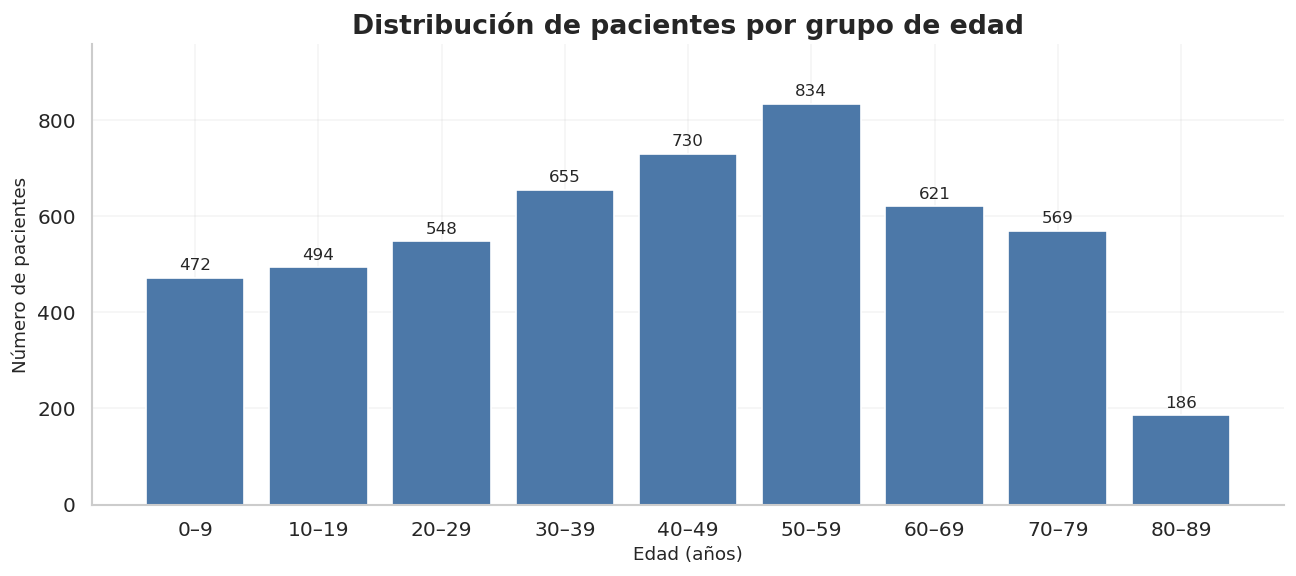

In [33]:
intervalos = np.arange(0, datosIctus["Edad"].max() + 11, 10)

edades = pd.cut(
    datosIctus["Edad"],
    bins=intervalos,
    right=False,
    include_lowest=True
).value_counts(sort=False)

fig, ax = plt.subplots(figsize=(11, 5))

barras = ax.bar(
    [f"{int(i.left)}–{int(i.right)-1}" for i in edades.index],
    edades.values,
    color=AZUL,
    edgecolor="white"
)

ax.bar_label(barras, padding=3, fontsize=10)

ax.set_title("Distribución de pacientes por grupo de edad")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Número de pacientes")
ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### **Variables Categoricas**

In [34]:
### Funcion para graficar variables categoricas
def graficar_categorica(columna, titulo, etiquetas=None):

    frecuencias = datosIctus[columna].value_counts()

    if etiquetas:
        frecuencias = frecuencias.rename(index=etiquetas)

    porcentajes = frecuencias / frecuencias.sum() * 100

    fig, ax = plt.subplots(figsize=(9, 3))

    barras = ax.barh(
        frecuencias.index.astype(str),
        frecuencias.values,
        color=AZUL,
        height=0.55
    )

    ax.bar_label(
        barras,
        labels=[
            f"{n:,} ({p:.1f}%)"
            for n, p in zip(frecuencias, porcentajes)
        ],
        padding=6
    )

    ax.invert_yaxis()
    ax.set_title(titulo, loc="left", pad=15)
    ax.set_xlabel("Número de pacientes")
    ax.set_ylabel("")
    ax.set_xlim(0, frecuencias.max() * 1.30)

    ax.grid(axis="y", visible=False)

    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

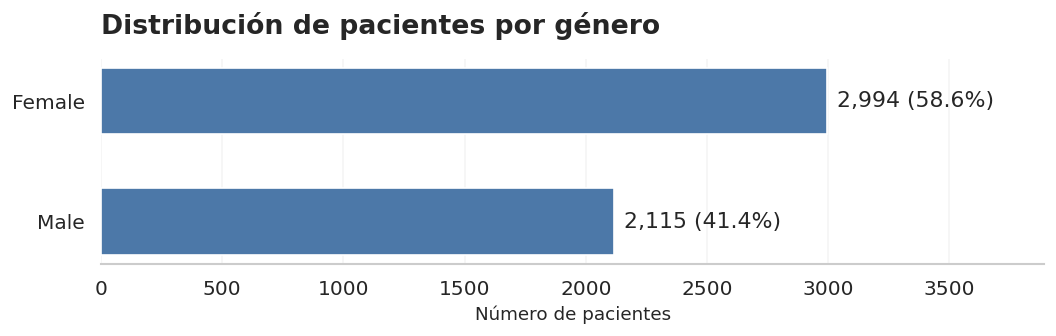

In [35]:
### Grafica de cantidad por Genero
graficar_categorica(
    columna="Genero",
    titulo="Distribución de pacientes por género",
)

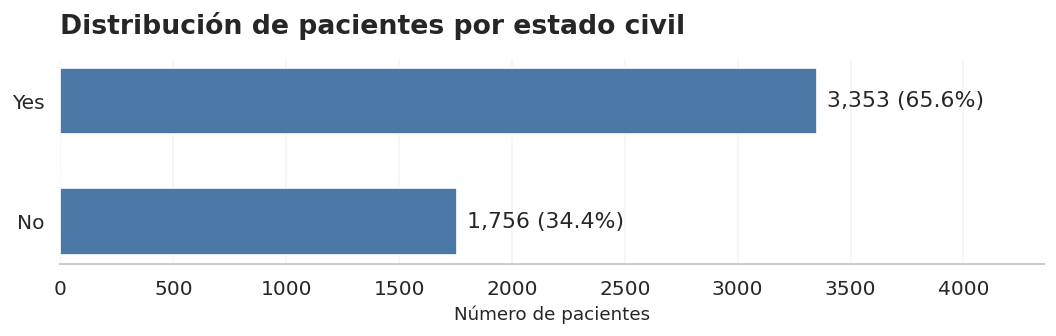

In [36]:
### Grafica de cantidad por Estado Civil
graficar_categorica(
    columna="Casado",
    titulo="Distribución de pacientes por estado civil",
)

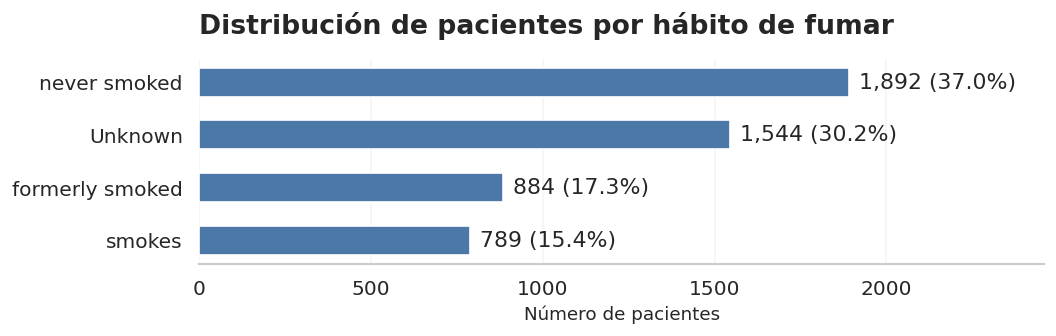

In [37]:
### Grafica de cantidad por Fumador
graficar_categorica(
    columna="Fumador",
    titulo="Distribución de pacientes por hábito de fumar",

)

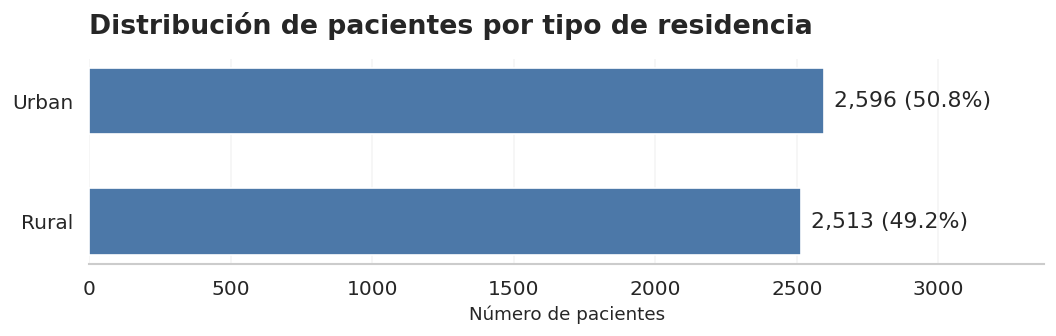

In [38]:
### Grafica de cantidad por Tipo residencia
graficar_categorica(
    columna="TipoResidencia",
    titulo="Distribución de pacientes por tipo de residencia",

)

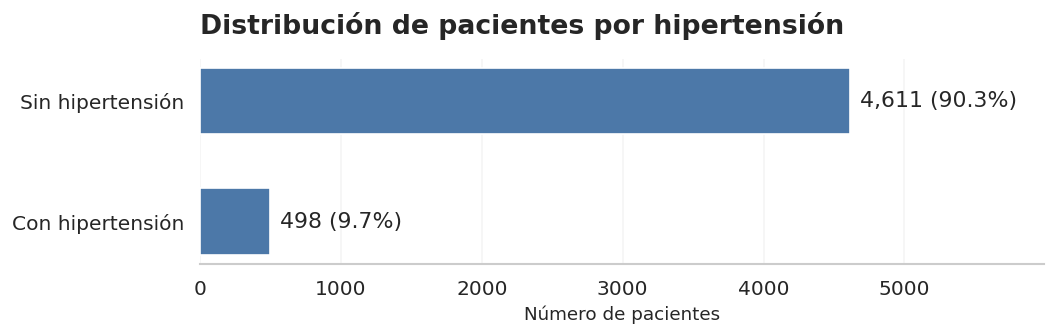

In [39]:
### Grafica de cantidad por Hipertension
graficar_categorica(
    columna="Hipertension",
    titulo="Distribución de pacientes por hipertensión",
    etiquetas={
        0: "Sin hipertensión",
        1: "Con hipertensión"
    }
)

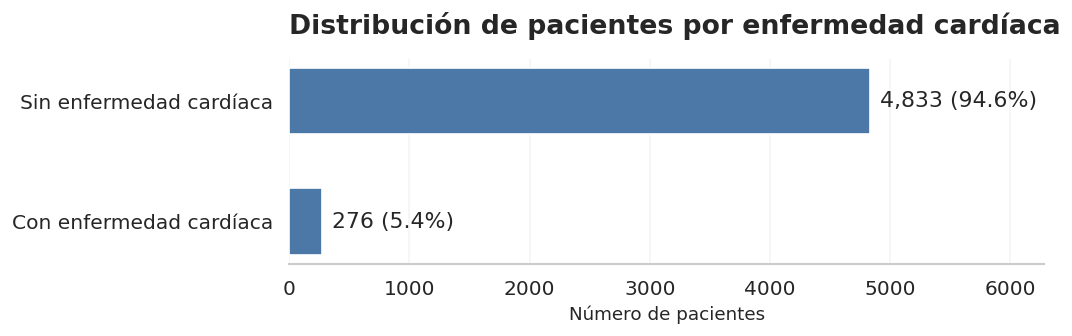

In [40]:
### Grafica de cantidad por Enfermedad Cardiaca
graficar_categorica(
    columna="EnfCardiaca",
    titulo="Distribución de pacientes por enfermedad cardíaca",
    etiquetas={
        0: "Sin enfermedad cardíaca",
        1: "Con enfermedad cardíaca"
    }
)

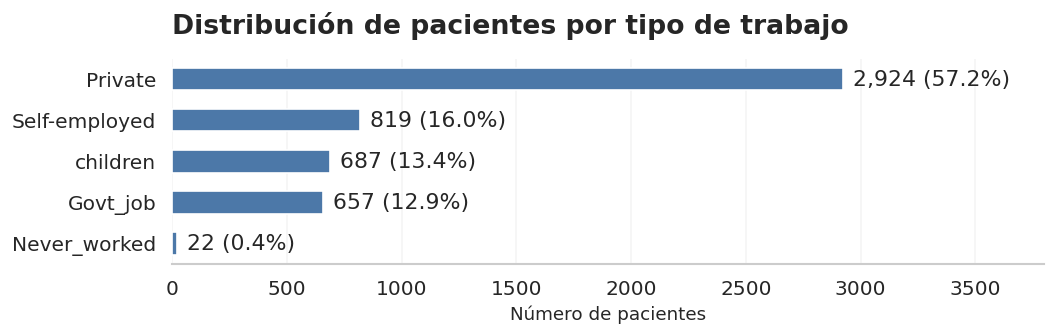

In [41]:
### Grafica de cantidad por Tipo Trabajo
graficar_categorica(
    columna="TipoTrabajo",
    titulo="Distribución de pacientes por tipo de trabajo",
)

**Variable Objetivo Derrame**

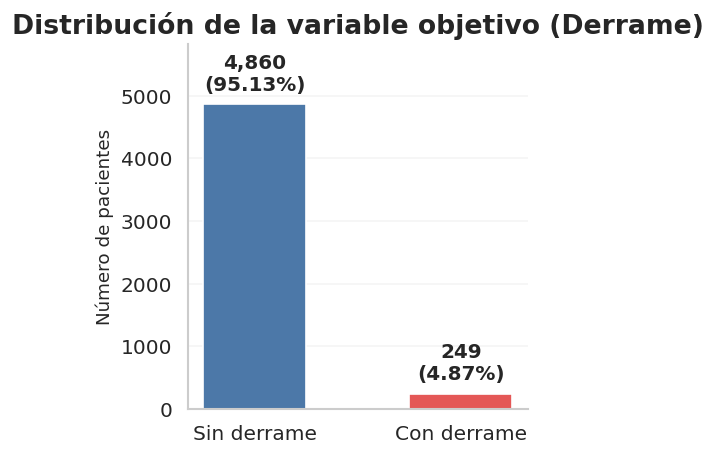

Relación de desbalance: 19.52:1


In [42]:
frecuencias = datosIctus["Derrame"].value_counts().reindex(
    [0, 1], fill_value=0
)

porcentajes = frecuencias / frecuencias.sum() * 100

fig, ax = plt.subplots(figsize=(4, 4))

barras = ax.bar(
    ["Sin derrame", "Con derrame"],
    frecuencias.values,
    color=[AZUL, ROJO],
    width=0.5
)

ax.bar_label(
    barras,
    labels=[
        f"{n:,}\n({p:.2f}%)"
        for n, p in zip(frecuencias, porcentajes)
    ],
    padding=6,
    fontsize=12,
    fontweight="bold"
)

ax.set_title("Distribución de la variable objetivo (Derrame)")
ax.set_ylabel("Número de pacientes")
ax.set_ylim(0, frecuencias.max() * 1.20)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

if frecuencias.min() > 0:
    ratio = frecuencias.max() / frecuencias.min()
    print(f"Relación de desbalance: {ratio:.2f}:1")


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Univariado Categorico</strong>

<p>
El principal hallazgo del análisis univariado categorico es el desbalance de la variable objetivo, donde el 95,13 % de los pacientes no ha sufrido un derrame cerebral, frente a únicamente un 4,87 % que sí lo ha sufrido. Esta distribución representa un desafío a futuro para el entrenamiento de los modelos, dado que podrían favorecer la clasificación de la clase mayoritaria. Por consiguiente, la exactitud no será suficiente para evaluar su desempeño, siendo necesario considerar métricas como Recall, Precision, F1-Score y PR-AUC.

Respecto a las variables clínicas, se observa una baja representación de pacientes con hipertensión (9,7 %) y enfermedades cardíacas (5,4 %). Sin embargo, dada su relevancia como factores de riesgo cerebrovascular, resulta pertinente estudiar su relación con la variable objetivo. Por otra parte, el 30,2 % de los pacientes presenta información desconocida sobre su hábito de fumar, lo que constituye una limitación en la calidad de los datos.

En cuanto a las características demográficas, existe una mayor concentración de pacientes entre los 40 y 69 años (42,8 %), mientras que el género y el tipo de residencia presentan distribuciones relativamente equilibradas. Asimismo, variables como el estado civil y el tipo de trabajo podrían presentar una dependencia respecto a la edad, sin embargo permiten caracterizar la población de estudio.
</p>

</div>



#### **Variables Numericas**

In [43]:
# Funcion para graficar variables numericas
def graficar_numerica(columna, titulo, xlabel, bins=30):

    valores = pd.to_numeric(
        datosIctus[columna],
        errors="coerce"
    ).dropna()

    media = valores.mean()
    mediana = valores.median()

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.histplot(
        valores,
        bins=bins,
        kde=True,
        color=AZUL,
        alpha=0.45,
        edgecolor="white",
        ax=ax
    )

    ax.axvline(
        media,
        color=ROJO,
        linestyle="--",
        linewidth=2,
        label=f"Media: {media:.2f}"
    )

    ax.axvline(
        mediana,
        color=VERDE,
        linestyle=":",
        linewidth=2,
        label=f"Mediana: {mediana:.2f}"
    )

    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Número de pacientes")
    ax.legend()

    plt.tight_layout()
    plt.show()

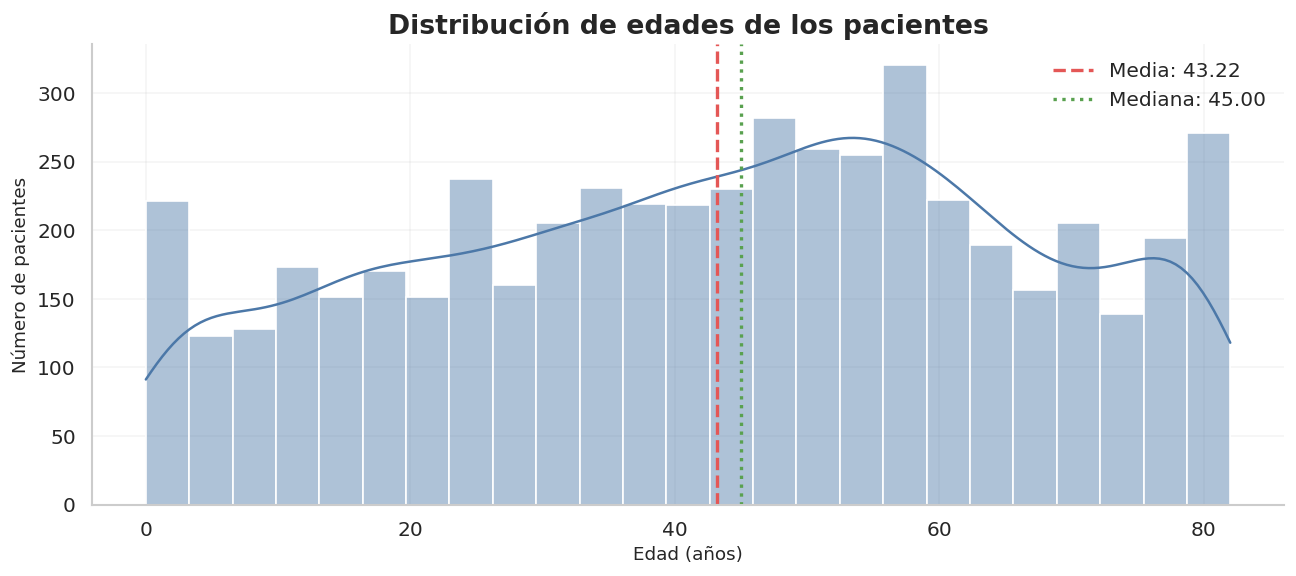

In [44]:
## Se requiere  un grafico por edades
graficar_numerica(
    columna="Edad",
    titulo="Distribución de edades de los pacientes",
    xlabel="Edad (años)",
    bins=25
)

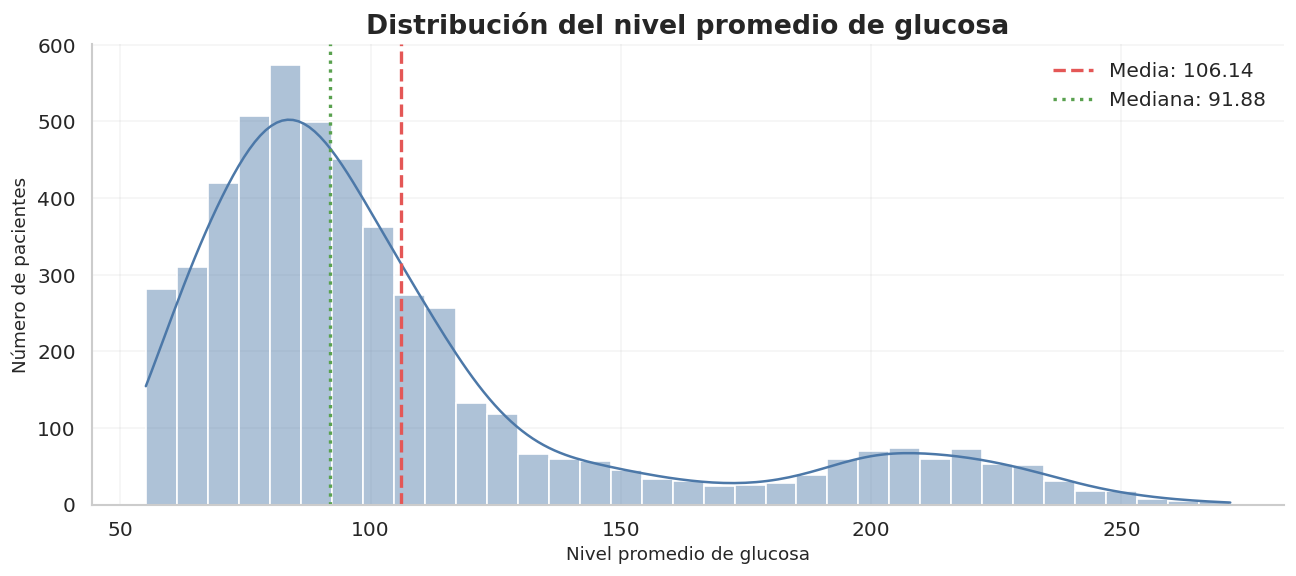

In [45]:
## Se requiere  un grafico por Nivel de glucosa
graficar_numerica(
    columna="PromedioNivelGlucosa",
    titulo="Distribución del nivel promedio de glucosa",
    xlabel="Nivel promedio de glucosa",
    bins=35
)

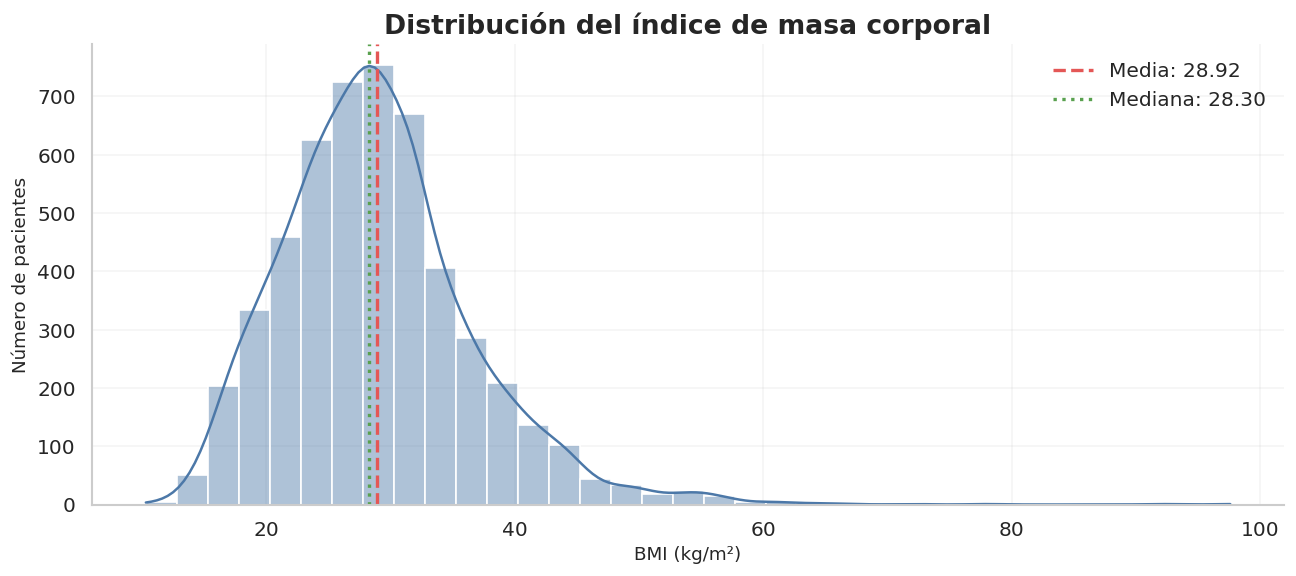

In [46]:
## Se requiere  un grafico por BMI
graficar_numerica(
    columna="BMI",
    titulo="Distribución del índice de masa corporal",
    xlabel="BMI (kg/m²)",
    bins=35
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Univariado Numerico</strong>

<p>
La distribución de la edad presenta una media de 43,22 años y una mediana de 45 años, cuya proximidad indica una asimetría poco pronunciada. Se observa una amplia representación de diferentes grupos de edades. Esta variabilidad permitirá estudiar cómo cambia la proporción de derrames cerebrales a medida que aumenta la edad.

El nivel promedio de glucosa presenta una marcada asimetría positiva, evidenciada por una media de 106,14 superior a la mediana de 91,88. La mayor parte de las observaciones se concentra entre 60 y 120, aunque se identifica una segunda concentración alrededor de 200 a 220.

Por último, el índice de masa corporal (BMI) presenta una distribución unimodal con asimetría positiva, una media de 28,92 kg/m² y una mediana de 28,30 kg/m². Con la mayoria de registros concentrada entre 20 y 40 kg/m². Asimismo es pertinente evaluar técnicas de escalamiento para reducir el impacto de las diferencias de magnitud entre las variables numéricas en los modelos sensibles a la escala.

</div>



### **3.2 - Analisis Bivariado**

In [47]:
### Funcion para graficas bivariadas con variables objetivo (Derrame)
def comparar_numerica(columna, titulo, xlabel):

    datos = datosIctus[
        [columna, "EstadoDerrame"]
    ].copy()

    datos[columna] = pd.to_numeric(
        datos[columna],
        errors="coerce"
    )

    datos = datos.dropna()

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.kdeplot(
        data=datos,
        x=columna,
        hue="EstadoDerrame",
        hue_order=["Sin derrame", "Con derrame"],
        palette=PALETA_DERRAME,
        common_norm=False,
        fill=True,
        alpha=0.20,
        linewidth=2.5,
        cut=0,
        ax=ax
    )

    ax.set_title(titulo, pad=15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Densidad")

    sns.move_legend(
        ax,
        "upper right",
        title="Estado del paciente"
    )

    plt.tight_layout()
    plt.show()

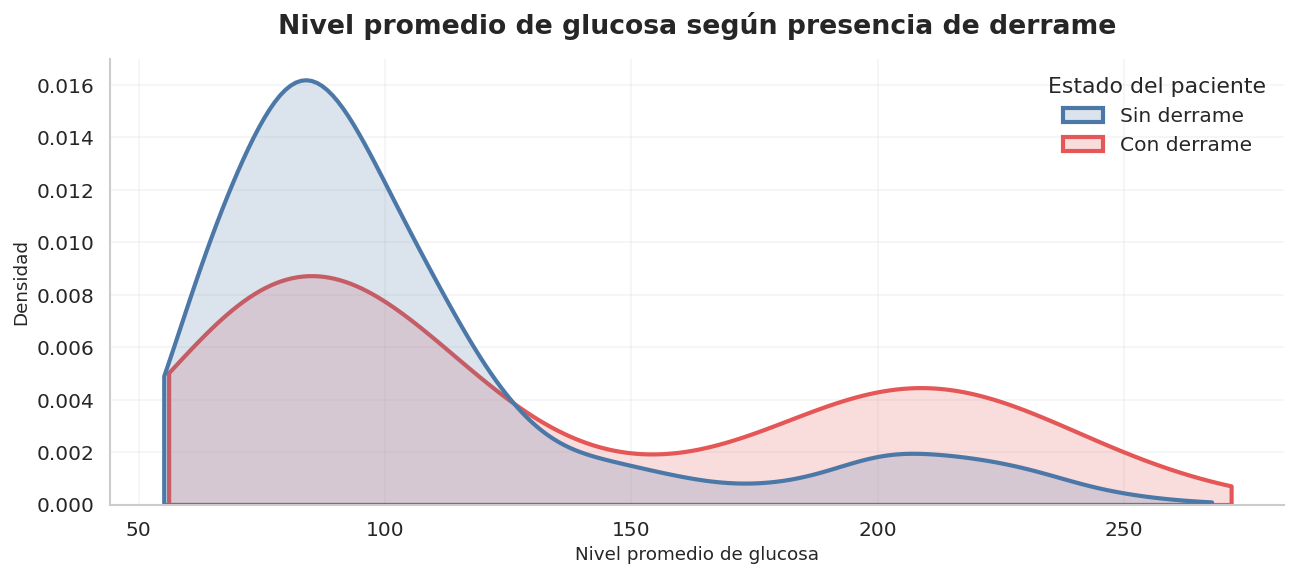

In [48]:
### Se requuiere grafica de Promedio de Nivel de Glucosa segun el Derrame Cerebral
comparar_numerica(
    columna="PromedioNivelGlucosa",
    titulo="Nivel promedio de glucosa según presencia de derrame",
    xlabel="Nivel promedio de glucosa"
)

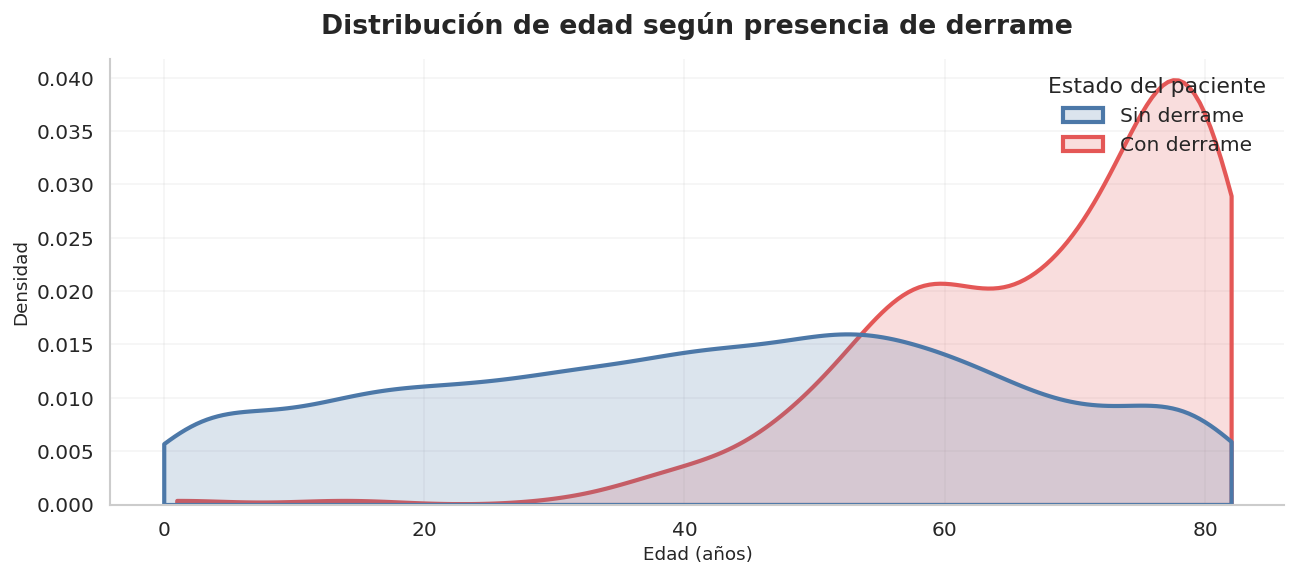

In [49]:
### Se requuiere grafica de Edad segun el Derrame Cerebral
comparar_numerica(
    columna="Edad",
    titulo="Distribución de edad según presencia de derrame",
    xlabel="Edad (años)"
)

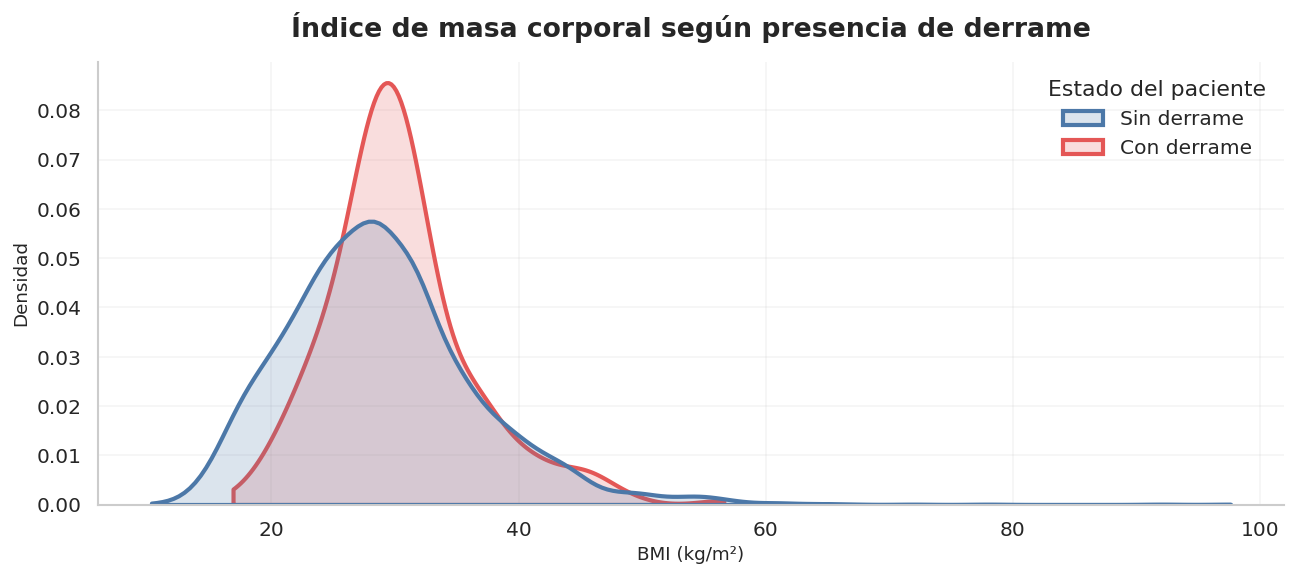

In [50]:
### Se requiere grafica de BMI segun el Derrame Cerebral
comparar_numerica(
    columna="BMI",
    titulo="Índice de masa corporal según presencia de derrame",
    xlabel="BMI (kg/m²)"
)

#### **Decision sobre Variables Categoricas**



<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Bivariado</strong>

<p>
La edad es la variable que presenta la mayor diferenciación entre los pacientes con y sin derrame cerebral. Mientras que los pacientes sin derrame presentan una distribución relativamente amplia, aquellos que han sufrido esta condición muestran una mayor concentración a partir de los 40 años, alcanzando su máxima densidad alrededor de los 78 años. Este comportamiento evidencia una asociación positiva entre la edad avanzada y la ocurrencia de derrames cerebrales, posicionándola como una característica con alto potencial predictivo.

El nivel promedio de glucosa también presenta diferencias relevantes entre ambas clases. Aunque las dos distribuciones alcanzan su primer pico alrededor de 85, los pacientes con derrame presentan una mayor densidad relativa por debajo de 125. Este comportamiento sugiere que los niveles bajos de glucosa están asociados con la ocurrencia de derrames cerebrales. Por ende, se creara una variable de <code>AltoRiesgo</code> para caracterizar a este grupo.

Por último, el índice de masa corporal (BMI) presenta una considerable superposición entre ambas distribuciones, aunque los pacientes con derrame muestran una mayor concentración alrededor de los 30 kg/m². En comparación con la edad y el nivel promedio de glucosa, esta variable evidencia una menor capacidad discriminativa individual. No obstante podría aportar información complementaria al combinarse con otras características clínicas. Estas observaciones representan asociaciones exploratorias cuya utilidad predictiva deberá validarse mediante  la evaluación de los modelos.
</p>
</div>


#### **Creacion de variable AltoRiesgo**

In [51]:

df04 = df03.withColumn('AltoRiesgo', F.when((F.col('Edad')>=40)& (F.col('PromedioNivelGlucosa')<=125),1).otherwise(0))

In [52]:
df04.show(5)

+-----+------+----+------------+-----------+------+-------------+--------------+--------------------+-----+---------------+-------+----------+
|   id|Genero|Edad|Hipertension|EnfCardiaca|Casado|  TipoTrabajo|TipoResidencia|PromedioNivelGlucosa|  BMI|        Fumador|Derrame|AltoRiesgo|
+-----+------+----+------------+-----------+------+-------------+--------------+--------------------+-----+---------------+-------+----------+
| 9046|  Male|  67|           0|          1|   Yes|      Private|         Urban|              228.69| 36.6|formerly smoked|      1|         0|
|51676|Female|  61|           0|          0|   Yes|Self-employed|         Rural|              202.21|30.72|   never smoked|      1|         0|
|31112|  Male|  80|           0|          1|   Yes|      Private|         Rural|              105.92| 32.5|   never smoked|      1|         1|
|60182|Female|  49|           0|          0|   Yes|      Private|         Urban|              171.23| 34.4|         smokes|      1|         0|

### **3.3 - Analisis en funcion de Alto Riesgo**

In [53]:
datosPandas = df04.toPandas()

### Funcion Auxiliar para graficar diferentes caracteristicas del paciente en funcion al riesgo
def graficar_riesgo(columna, titulo, etiquetas=None):

    resumen = (
        datosPandas
        .groupby(["AltoRiesgo", columna], observed=True)
        .agg(
            TotalPacientes=("Derrame", "count"),
            TotalDerrames=("Derrame", "sum")
        )
        .reset_index()
    )

    resumen["Porcentaje"] = (
        resumen["TotalDerrames"] /
        resumen["TotalPacientes"] * 100
    )

    resumen["GrupoRiesgo"] = resumen["AltoRiesgo"].map({
        0: "Sin alto riesgo",
        1: "Con alto riesgo"
    })

    if etiquetas:
        resumen[columna] = resumen[columna].replace(etiquetas)

    categorias = resumen[columna].unique().tolist()

    grupos = [
        "Sin alto riesgo",
        "Con alto riesgo"
    ]

    posiciones = np.arange(len(categorias))
    ancho = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))

    for i, (grupo, color) in enumerate(
        zip(grupos, [AZUL, ROJO])
    ):

        datos_grupo = (
            resumen[resumen["GrupoRiesgo"] == grupo]
            .set_index(columna)
            .reindex(categorias)
        )

        barras = ax.bar(
            posiciones + (i - 0.5) * ancho,
            datos_grupo["Porcentaje"],
            width=ancho,
            color=color,
            label=grupo
        )

        labels = [
            f"{p:.1f}%\n(n={int(n)})"
            if pd.notna(p) else ""
            for p, n in zip(
                datos_grupo["Porcentaje"],
                datos_grupo["TotalPacientes"]
            )
        ]

        ax.bar_label(
            barras,
            labels=labels,
            padding=4,
            fontsize=9
        )

    ax.set_xticks(posiciones)
    ax.set_xticklabels(categorias)

    ax.set_title(titulo, pad=20)
    ax.set_xlabel("")
    ax.set_ylabel("Pacientes con derrame (%)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(100))
    
    ax.set_ylim(
        0,
        resumen["Porcentaje"].max() * 1.35 + 2
    )

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=2
    )

    ax.grid(axis="x", visible=False)

    plt.tight_layout()
    plt.show()

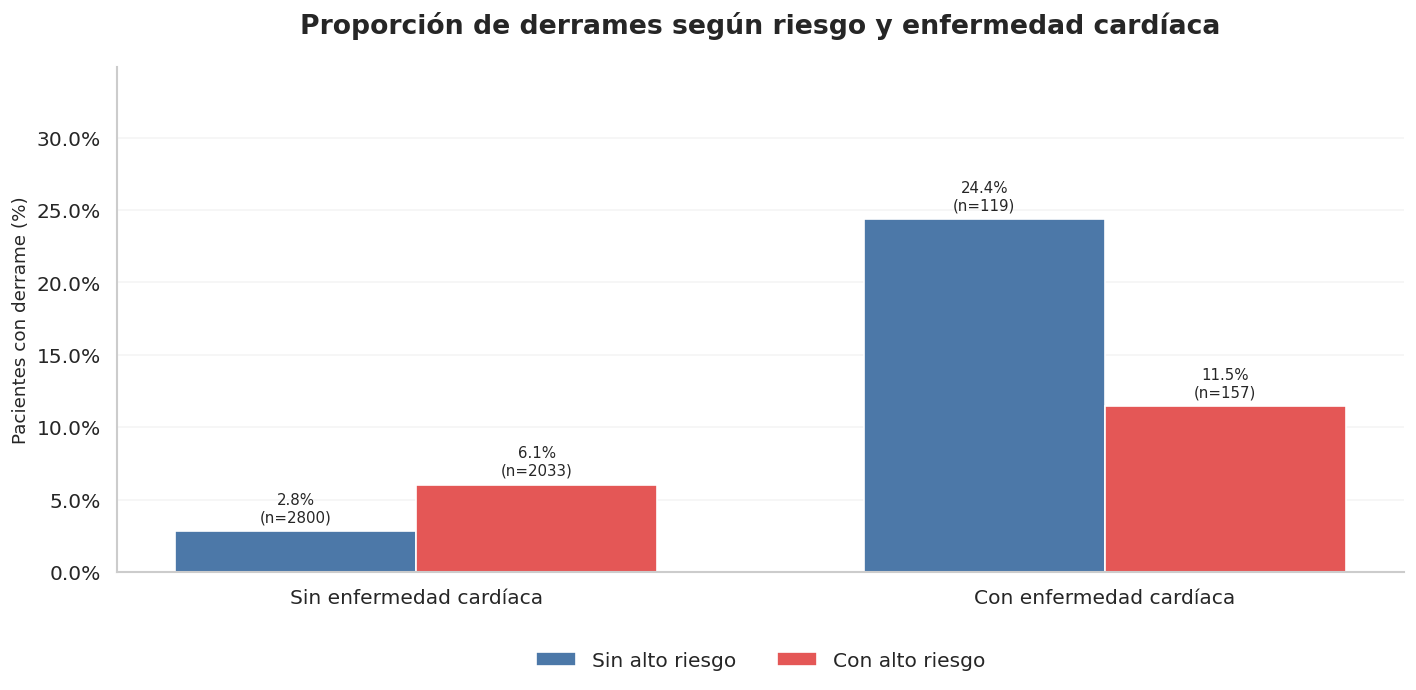

In [54]:
### Graficas en funcion de Alto Riesgo
# Alto Riesgo contra Derrame Cerebral: Enfermedad Cardiaca
graficar_riesgo(
    columna="EnfCardiaca",
    titulo="Proporción de derrames según riesgo y enfermedad cardíaca",
    etiquetas={
        0: "Sin enfermedad cardíaca",
        1: "Con enfermedad cardíaca"
    }
)

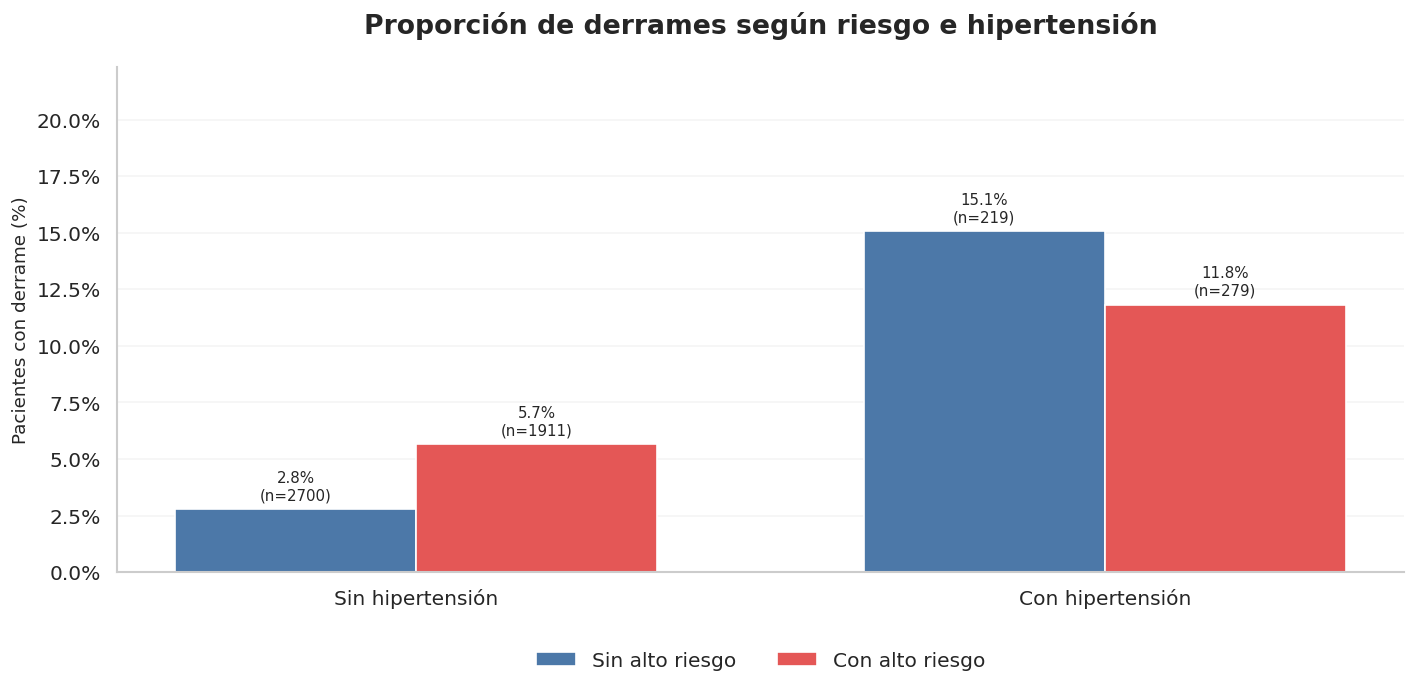

In [55]:
# Alto Riesgo contra Derramet Cerebral: Hipertension
graficar_riesgo(
    columna="Hipertension",
    titulo="Proporción de derrames según riesgo e hipertensión",
    etiquetas={
        0: "Sin hipertensión",
        1: "Con hipertensión"
    }
)


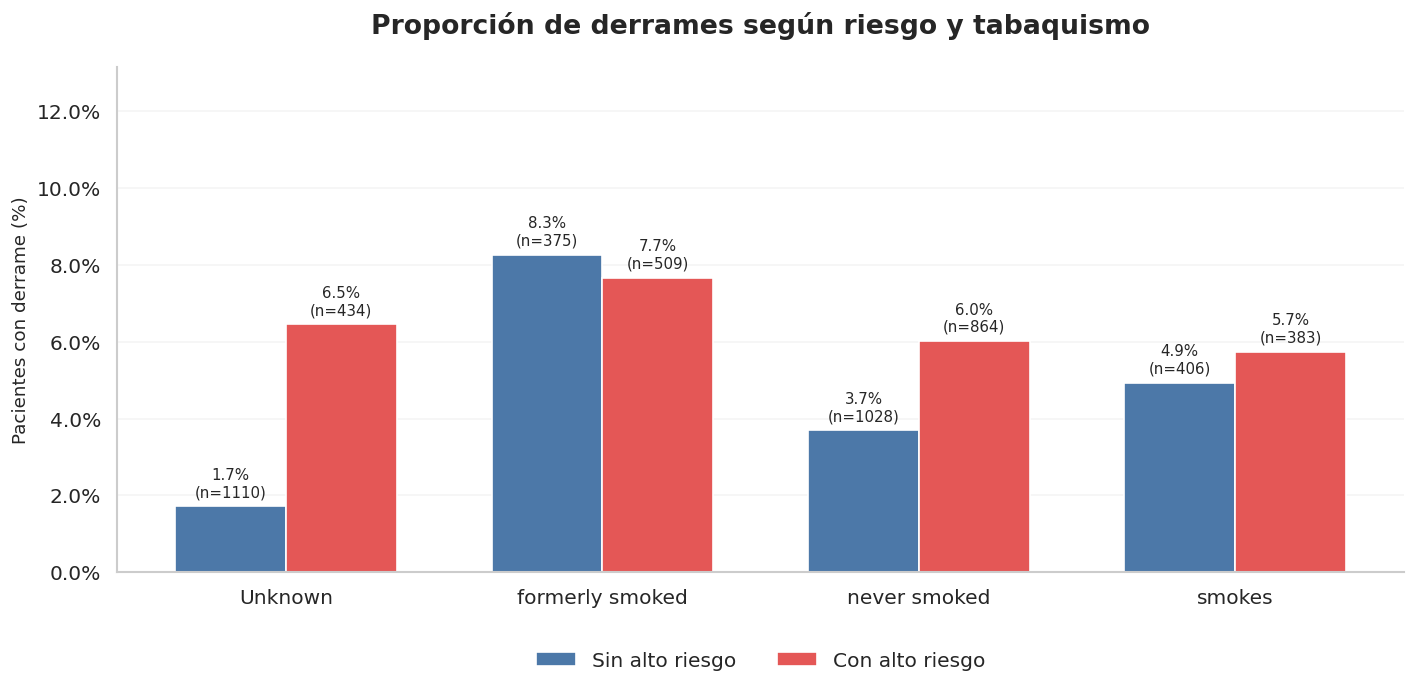

In [56]:
# Alto Riesgo contra Derramet Cerebral: Fumador


graficar_riesgo(
    columna="Fumador",
    titulo="Proporción de derrames según riesgo y tabaquismo",
)

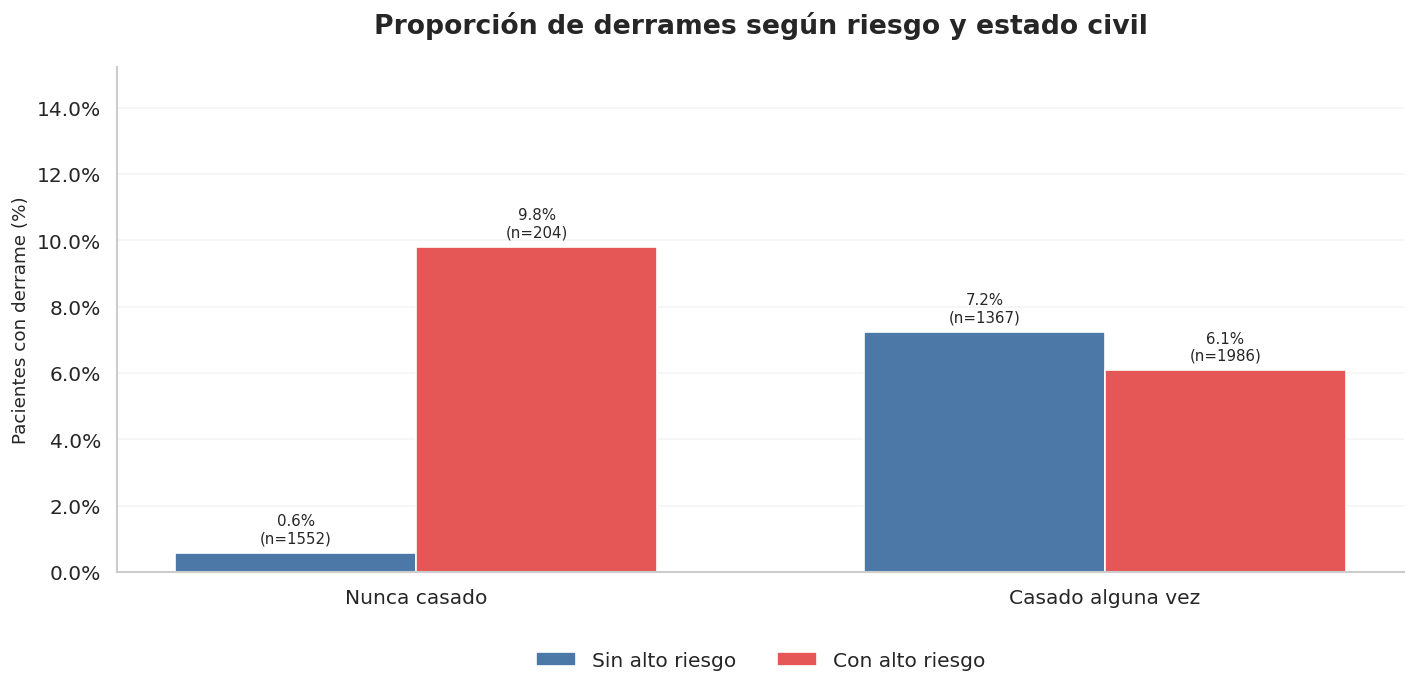

In [57]:
# Alto Riesgo contra Derramet Cerebral: Estado Civil

graficar_riesgo(
    columna="Casado",
    titulo="Proporción de derrames según riesgo y estado civil",
    etiquetas={
        "Yes": "Casado alguna vez",
        "No": "Nunca casado"
    }
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis en funcion variable AltoRiesgo</strong>

<p>
El análisis de la variable AltoRiesgo en combinación con las características clínicas evidencia que los pacientes con enfermedades cardíacas e hipertensión presentan mayores proporciones de derrames cerebrales, independientemente de su clasificación de riesgo. Sin embargo, se observa un comportamiento contrario al esperado: entre los pacientes con enfermedades cardíacas, la proporción de derrames es superior en el grupo sin alto riesgo (24,4 %) respecto al grupo con alto riesgo (11,5 %). Un comportamiento similar se presenta en los pacientes con hipertensión, con proporciones del 15,1 % y 11,8 %, respectivamente. Asimismo, los pacientes con hábito de fumar desconocido presentan un incremento del 1,7 % al 6,5 %.

En general, los resultados indican que la característica AltoRiesgo permite identificar grupos con una mayor proporción de derrames cerebrales, aunque su comportamiento no es consistente en todas las categorías analizadas. Esto sugiere que el criterio establecido mediante la combinación de edad y nivel promedio de glucosa presenta limitaciones para representar el riesgo cerebrovascular de manera generalizada. Por consiguiente se mantendran las variables originales y se evaluara posteriormente si la incorporación de la variable <code>AltoRiesgo</code> contribuye efectivamente al desempeño de los modelos de clasificación.
</p>
</div>


#### Nota: La preparacion  de los datos no ha sido del todo satisfactoria, se debe realizar mejor estudio sobre todo de los outliers o compartamientos atipicos entre otros.



## **4 - Implementacion de Modelos de Machine Learning usando MLlib**

- Creacion de vector de caracteristicas
- Division de datos para entrenamiento y prueba
- Se ejecutan los modelos seleccionados
- Se evaluan los modelos con las metricas de rendimiento

### **Transformacion de Variables Categoricas**

In [58]:
### Se separan variables categoricas

nocategorias = ['id','Edad','Hipertension','EnfCardiaca','PromedioNivelGlucosa','BMI','Derrame','AltoRiesgo']

### Se realiza los indices en funcion de su posicion [0,1,2...]

indices = [StringIndexer(inputCol= variable , outputCol=variable+"_IND").fit(df04)
           for variable in list(set(df04.columns)-set(nocategorias))
]

### Se realiza tuberia para etapa de cambuo de categoria a numericos
tuberia = Pipeline(stages = indices)

### Se crea nueva version

df05 = tuberia.fit(df04).transform(df04)

### Se borran las columnas con variables categoricas
varCategoricas = ['id', 'Genero', 'Casado', 'TipoTrabajo', 'TipoResidencia', 'Fumador']

df05 = df05.drop(*varCategoricas)

df05.show(4)




+----+------------+-----------+--------------------+-----+-------+----------+------------------+----------+-----------+---------------+----------+
|Edad|Hipertension|EnfCardiaca|PromedioNivelGlucosa|  BMI|Derrame|AltoRiesgo|TipoResidencia_IND|Casado_IND|Fumador_IND|TipoTrabajo_IND|Genero_IND|
+----+------------+-----------+--------------------+-----+-------+----------+------------------+----------+-----------+---------------+----------+
|  67|           0|          1|              228.69| 36.6|      1|         0|               0.0|       0.0|        2.0|            0.0|       1.0|
|  61|           0|          0|              202.21|30.72|      1|         0|               1.0|       0.0|        0.0|            1.0|       0.0|
|  80|           0|          1|              105.92| 32.5|      1|         1|               1.0|       0.0|        0.0|            0.0|       1.0|
|  49|           0|          0|              171.23| 34.4|      1|         0|               0.0|       0.0|        3.0

### **Creacion Vector de Caracteristicas**

In [59]:
## Se realiza el vector de Categorias:
varIndependientes = VectorAssembler(inputCols=df05.drop('Derrame').columns, outputCol='independientes')


vectorIndependientes = varIndependientes.transform(df05).select('independientes','Derrame')


## Se observa el vector 

vectorIndependientes.show(5,False)


+--------------------------------------------------+-------+
|independientes                                    |Derrame|
+--------------------------------------------------+-------+
|(11,[0,2,3,4,8,10],[67.0,1.0,228.69,36.6,2.0,1.0])|1      |
|(11,[0,3,4,6,9],[61.0,202.21,30.72,1.0,1.0])      |1      |
|[80.0,0.0,1.0,105.92,32.5,1.0,1.0,0.0,0.0,0.0,1.0]|1      |
|(11,[0,3,4,8],[49.0,171.23,34.4,3.0])             |1      |
|(11,[0,1,3,4,6,9],[79.0,1.0,174.12,24.0,1.0,1.0]) |1      |
+--------------------------------------------------+-------+
only showing top 5 rows



### **Division de datos para entrenamiento y prueba (prueba = 20% de los datos)**

In [60]:
### Se crea un dataframe spark edsde el vector

df06 = vectorIndependientes.select(['independientes','Derrame'])

# train = conjunto de entrenamiento 80% datos
# test = conjunto de prueba 20% datos

train, test = df06.randomSplit([0.8, 0.2], seed=42)

train = train.cache()
test = test.cache()

print(f"Registros de entrenamiento: {train.count()}")
print(f"Registros de prueba: {test.count()}")

print("Distribución de clases en entrenamiento:")
train.groupBy("Derrame").count().show()

print("Distribución de clases en prueba:")
test.groupBy("Derrame").count().show()

Registros de entrenamiento: 4122
Registros de prueba: 987
Distribución de clases en entrenamiento:
+-------+-----+
|Derrame|count|
+-------+-----+
|      1|  202|
|      0| 3920|
+-------+-----+

Distribución de clases en prueba:
+-------+-----+
|Derrame|count|
+-------+-----+
|      1|   47|
|      0|  940|
+-------+-----+



In [61]:
totalTrain = train.count()

conDerrameTrain = train.filter(
    F.col("Derrame") == 1
).count()

noDerrameTrain = totalTrain - conDerrameTrain

porcentajeConDerrameTrain = (
    conDerrameTrain / totalTrain
) * 100

print("Conjunto de Entrenamiento")
print(f"Cantidad de pacientes con derrame: {conDerrameTrain}")
print(f"Cantidad de pacientes sin derrame: {noDerrameTrain}")
print(f"Porcentaje con derrame: {porcentajeConDerrameTrain:.2f}%")

Conjunto de Entrenamiento
Cantidad de pacientes con derrame: 202
Cantidad de pacientes sin derrame: 3920
Porcentaje con derrame: 4.90%


### **Funciones Auxiliares para Evaluacion de modelos**

In [62]:
### Evaluacion de Modelos con las siguientes metricas 
### AUC-ROC	Capacidad de diferenciación entre ambas clases a través de distintos umbrales.
### PR-AUC	Rendimiento sobre la clase positiva ante el desbalance de clases.
### Accuracy	Proporción total de predicciones correctas.
### Precision	Proporción de derrames predichos que realmente corresponden a derrames.
### Recall	Proporción de derrames reales identificados correctamente.
### F1-Score Media armónica entre Precision y Recall.
def evaluar_modelo(predicciones, nombre):

    evaluadorROC = BinaryClassificationEvaluator(
        labelCol="Derrame",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )

    evaluadorPR = BinaryClassificationEvaluator(
        labelCol="Derrame",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderPR"
    )

    evaluadorMulti = MulticlassClassificationEvaluator(
        labelCol="Derrame",
        predictionCol="prediction",
        metricLabel=1.0
    )

    resultados = {
        "Modelo": nombre,

        "AUC-ROC": evaluadorROC.evaluate(predicciones),

        "PR-AUC": evaluadorPR.evaluate(predicciones),

        "Accuracy": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "accuracy"}
        ),

        "Precision": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "weightedPrecision"}
        ),

        "Recall": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "weightedRecall"}
        ),

        "F1-Score": evaluadorMulti.evaluate(
            predicciones,
            {evaluadorMulti.metricName: "weightedFMeasure"}
        )
    }



    print(f"Resultados: {nombre}")
    print("-" * 40)

    for metrica, valor in resultados.items():
        if metrica != "Modelo":
            print(f"{metrica}: {valor:.4f}")

    return resultados

In [63]:
### Matriz de Confusion
def graficar_matriz_confusion(predicciones, nombre):

    conteos = (
        predicciones
        .groupBy("Derrame", "prediction")
        .count()
        .collect()
    )

    matriz = np.zeros((2, 2), dtype=int)

    for fila in conteos:
        matriz[
            int(fila["Derrame"]),
            int(fila["prediction"])
        ] = fila["count"]

    porcentajes = matriz / matriz.sum() * 100

    etiquetas = np.array([
        [
            f"{matriz[i, j]:,}\n({porcentajes[i, j]:.2f}%)"
            for j in range(2)
        ]
        for i in range(2)
    ])

    fig, ax = plt.subplots(figsize=(7, 5))

    sns.heatmap(
        matriz,
        annot=etiquetas,
        fmt="",
        cmap="Blues",
        cbar=False,
        linewidths=1,
        xticklabels=["Sin derrame", "Con derrame"],
        yticklabels=["Sin derrame", "Con derrame"],
        annot_kws={"size": 13},
        ax=ax
    )

    ax.set_title(
        f"Matriz de confusión — {nombre}",
        pad=20
    )

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [64]:
### Curvas ROC y Precision-Recall
def graficar_curvas(predicciones, nombre, resultados):

    datosCurvas = predicciones.select(
        "Derrame",
        vector_to_array("probability")[1].alias("Probabilidad")
    ).toPandas()

    yReal = datosCurvas["Derrame"]
    yProb = datosCurvas["Probabilidad"]

    fpr, tpr, _ = roc_curve(yReal, yProb)

    precision, recall, _ = precision_recall_curve(
        yReal, yProb
    )

    proporcionPositiva = yReal.mean()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Curva ROC
    axes[0].plot(
        fpr,
        tpr,
        color="#4C78A8",
        linewidth=2.5,
        label=f"AUC-ROC: {resultados['AUC-ROC']:.4f}"
    )

    axes[0].fill_between(
        fpr, tpr,
        color="#4C78A8",
        alpha=0.12
    )

    axes[0].plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        label="Clasificador aleatorio"
    )

    axes[0].set_title("Curva ROC")
    axes[0].set_xlabel("Tasa de falsos positivos")
    axes[0].set_ylabel("Tasa de verdaderos positivos")
    axes[0].legend(loc="lower right")

    # Curva Precision-Recall
    axes[1].plot(
        recall,
        precision,
        color="#E45756",
        linewidth=2.5,
        label=f"PR-AUC: {resultados['PR-AUC']:.4f}"
    )

    axes[1].fill_between(
        recall, precision,
        color="#E45756",
        alpha=0.12
    )

    axes[1].axhline(
        proporcionPositiva,
        linestyle="--",
        color="gray",
        label=f"Línea base: {proporcionPositiva:.4f}"
    )

    axes[1].set_title("Curva Precision-Recall")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend(loc="upper right")

    for ax in axes:
        ax.set_xlim(0, 1.02)
        ax.set_ylim(0, 1.02)

    fig.suptitle(
        f"Evaluación de curvas — {nombre}",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

### **4.1 - Modelo Regresion Logistica**

Es un algoritmo de aprendizaje supervisado que estima la probabilidad de pertenencia a una clase mediante la función logística aplicada a una combinación lineal de las características de entrada.

In [65]:

# Se instancia el modelo de regresion Logistica
RegreLog = LogisticRegression(featuresCol="independientes", labelCol="Derrame")

# Se aplica el modelo de regresion logistica sobre los datos de entrenamiento: "se entrena el modelo"
modeloRegLog = RegreLog.fit(train)

### Evaluacion Regresion Logistica

Resultados: Regresión Logística
----------------------------------------
AUC-ROC: 0.8187
PR-AUC: 0.1410
Accuracy: 0.9524
Precision: 0.9070
Recall: 0.9524
F1-Score: 0.9292


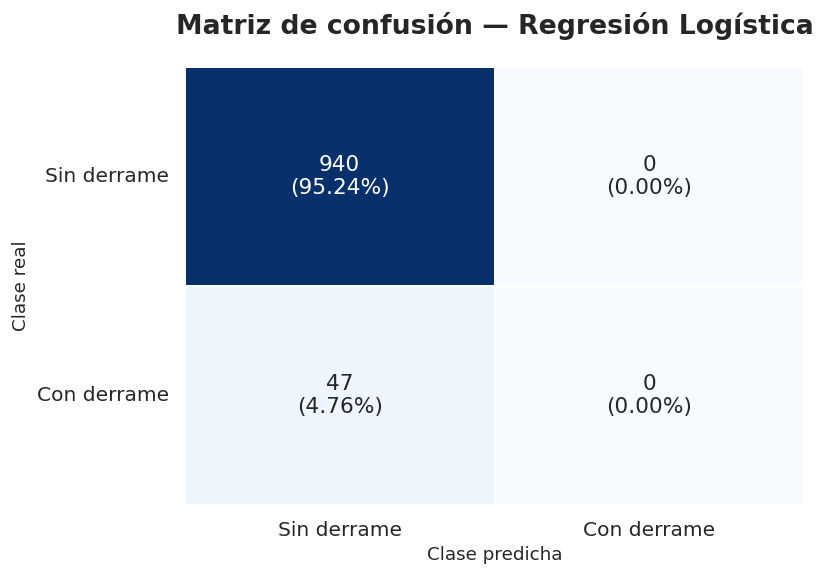

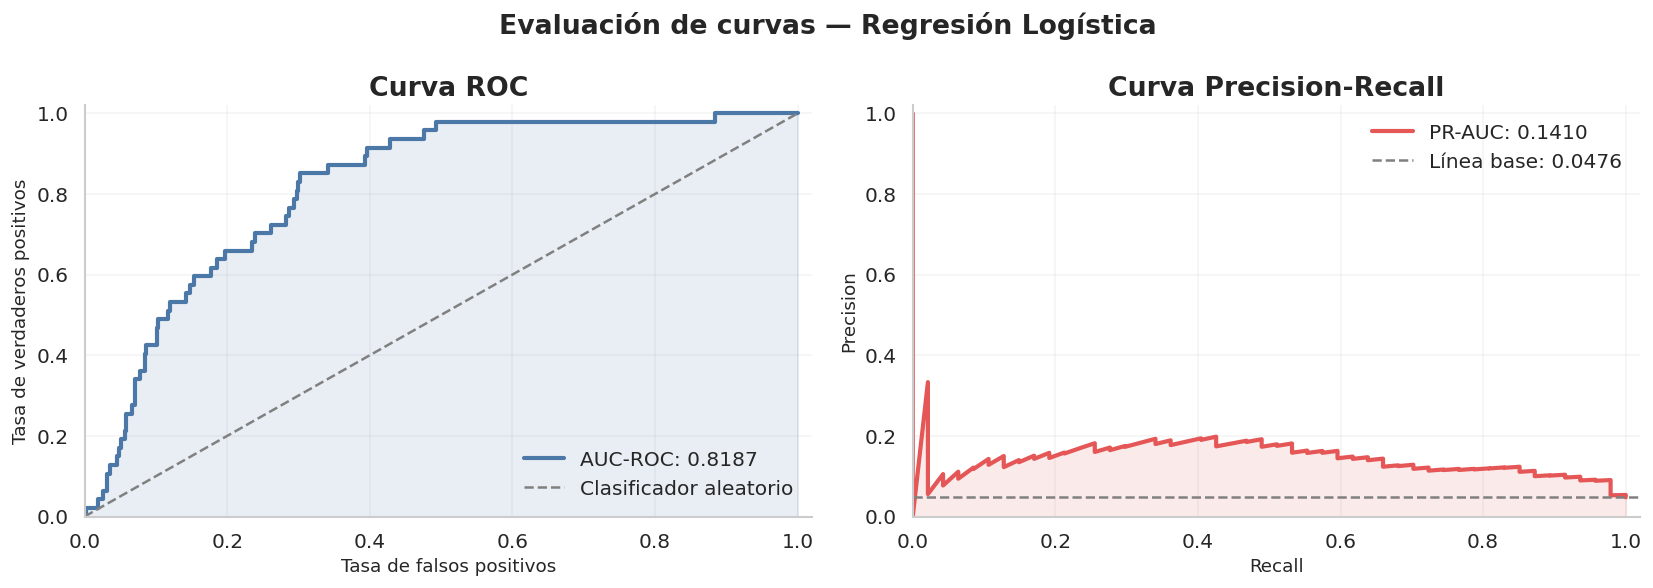

In [66]:
predRLog = modeloRegLog.transform(test)

resultadosRLog = evaluar_modelo(
    predRLog,
    "Regresión Logística"
)

graficar_matriz_confusion(
    predRLog,
    "Regresión Logística"
)

graficar_curvas(
    predRLog,
    "Regresión Logística",
    resultadosRLog
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Regresion Logistica</strong>

<p>
La Regresión Logística presenta un AUC-ROC de 0,8187, lo que indica una buena capacidad discriminativa entre pacientes con y sin derrame cerebral. Asimismo, obtiene un PR-AUC de 0,1410, aproximadamente 3 veces superior a la línea base de 0,0476. Si bien estos resultados evidencian que el modelo ha aprendido patrones relevantes para diferenciar ambas clases, la curva Precision-Recall refleja dificultades para mantener una precisión elevada a medida que aumenta la identificación de casos positivos.

Aunque el modelo alcanza un Accuracy del 95,24 %, una Precision ponderada del 90,70 % y un F1-Score ponderado del 92,92 %, la matriz de confusión evidencia una limitación considerable: clasifica todas las observaciones como pacientes sin derrame. En consecuencia, identifica correctamente los 942 casos negativos, pero genera 47 falsos negativos, sin identificar ningún caso positivo.

En conclusión, la Regresión Logística presenta una buena capacidad para ordenar las observaciones según su probabilidad de pertenecer a la clase positiva, pero resulta ineficaz para identificar pacientes con derrame cerebral bajo el umbral de clasificación predeterminado.
</p>
</div>


### **4.2 - Modelo Decision Tree**

Es un algoritmo de aprendizaje supervisado que realiza divisiones sucesivas de los datos mediante reglas de decisión, buscando maximizar la homogeneidad de las clases en cada nodo.

In [67]:
# Se instancia Modelo
ArbolDecision = DecisionTreeClassifier(
    featuresCol="independientes",
    labelCol="Derrame",
    maxDepth=5,
    minInstancesPerNode=5,
    impurity="gini",
    maxBins=32,
    seed=42
)

# Se entrena Modelo
modeloArbolDecision = ArbolDecision.fit(train)

Resultados: Decision Tree
----------------------------------------
AUC-ROC: 0.7005
PR-AUC: 0.1289
Accuracy: 0.9473
Precision: 0.9068
Recall: 0.9473
F1-Score: 0.9266


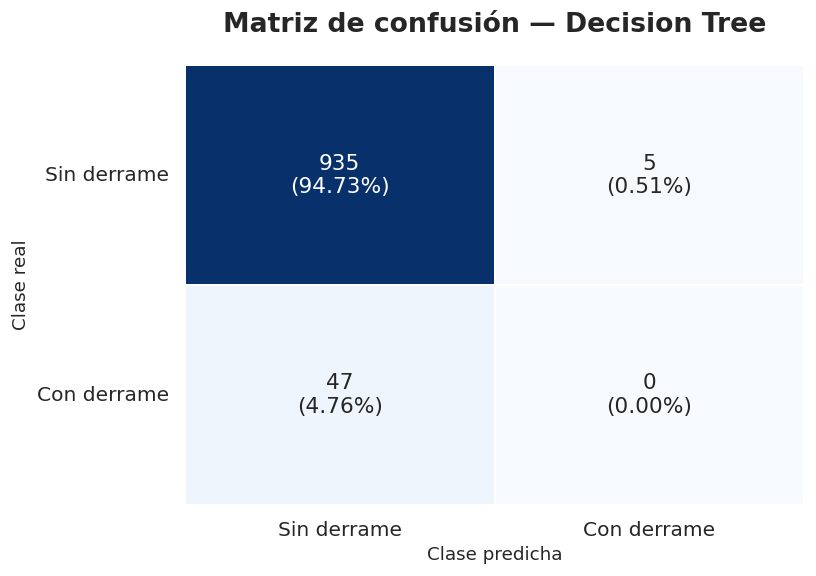

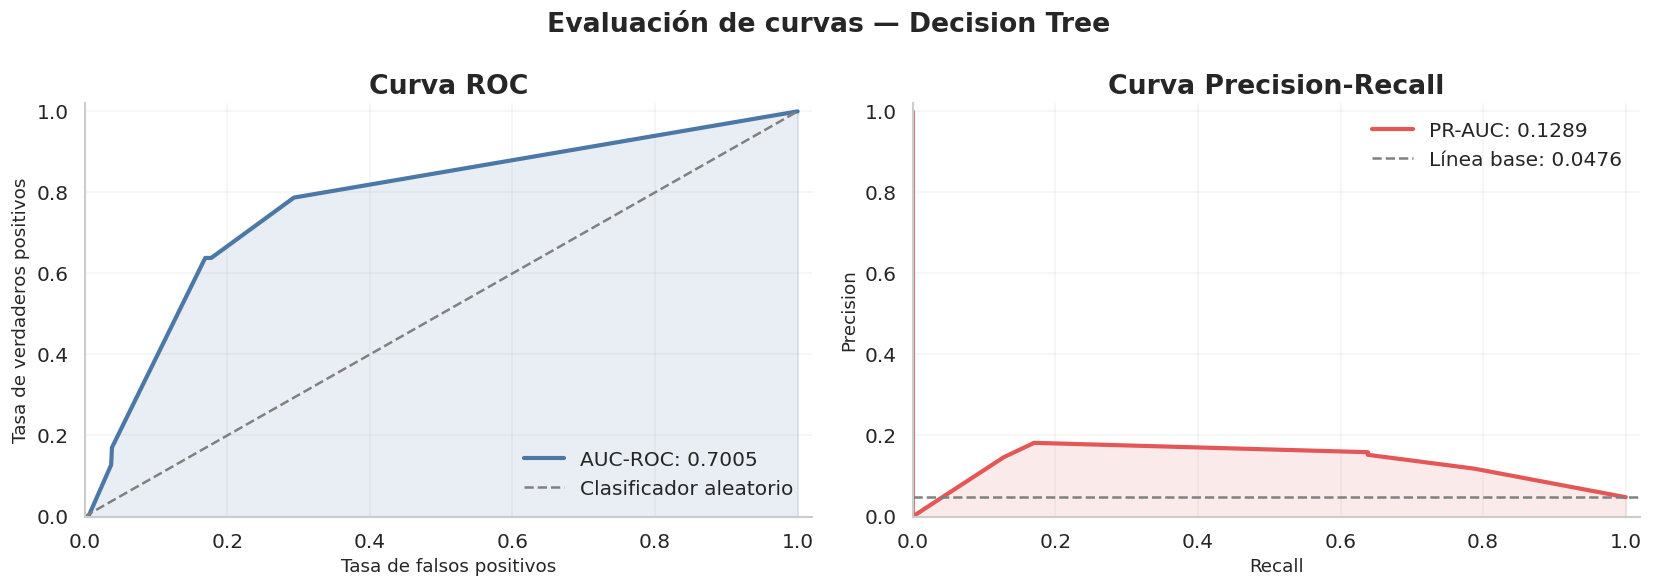

In [68]:
predArbolDecision = modeloArbolDecision.transform(test)

resultadosArbolDecision = evaluar_modelo(
    predArbolDecision,
    "Decision Tree"
)

graficar_matriz_confusion(
    predArbolDecision,
    "Decision Tree"
)

graficar_curvas(
    predArbolDecision,
    "Decision Tree",
    resultadosArbolDecision
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Decision Tree</strong>

El modelo Decision Tree presenta un AUC-ROC de 0,7005, lo que indica una capacidad discriminativa moderada entre pacientes con y sin derrame cerebral. Asimismo, obtiene un PR-AUC de 0,1289, aproximadamente 2,7 veces superior a la línea base de 0,0476. Aunque estos resultados reflejan cierto aprendizaje de patrones, las curvas ROC y Precision-Recall evidencian una capacidad limitada para diferenciar ambas clases mediante distintos umbrales de clasificación.

El modelo clasifica correctamente 935 pacientes sin derrame, genera 5 falsos positivos y 47 falsos negativos, sin identificar ningún caso positivo. Lo anterior demuestra que el rendimiento general está condicionado por el predominio de la clase mayoritaria. El árbol de decisión, pese a su capacidad para representar relaciones no lineales e interacciones entre características, no logra identificar correctamente a los pacientes con derrame cerebral bajo la configuración utilizada.
<p>

</p>
</div>


### **4.3 - Modelo Random Forest**

Es un algoritmo de aprendizaje por conjuntos (Ensemble Learning) basado en la técnica de Bagging, que combina múltiples árboles de decisión entrenados mediante muestras aleatorias de los datos y subconjuntos de características.

In [69]:
# Instancia Modelo
BosqueAleatorio = RandomForestClassifier(
    featuresCol="independientes",
    labelCol="Derrame",
    numTrees=100,
    maxDepth=5,
    minInstancesPerNode=5,
    featureSubsetStrategy="sqrt",
    subsamplingRate=1.0,
    impurity="gini",
    maxBins=32,
    seed=42
)
# Entrenamiento Modelo
modeloRandomForest = BosqueAleatorio.fit(train)

Resultados: Random Forest
----------------------------------------
AUC-ROC: 0.8229
PR-AUC: 0.1430
Accuracy: 0.9524
Precision: 0.9070
Recall: 0.9524
F1-Score: 0.9292


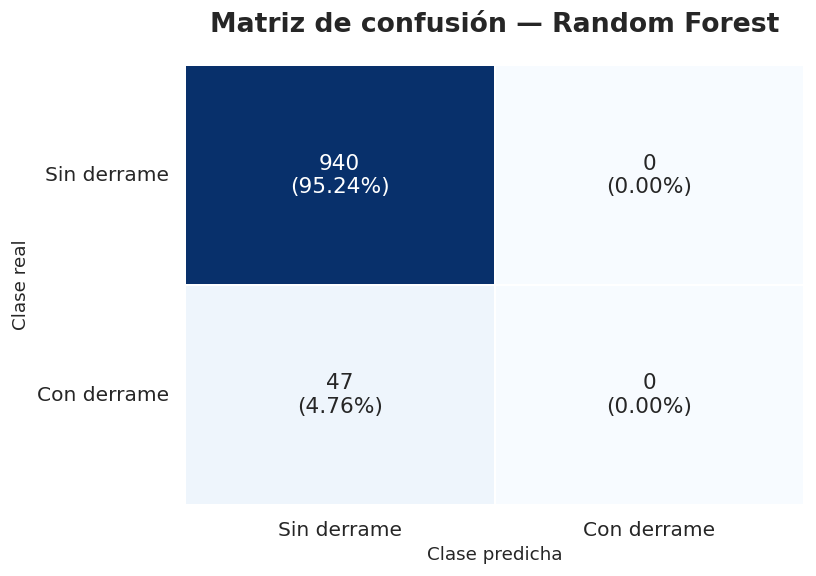

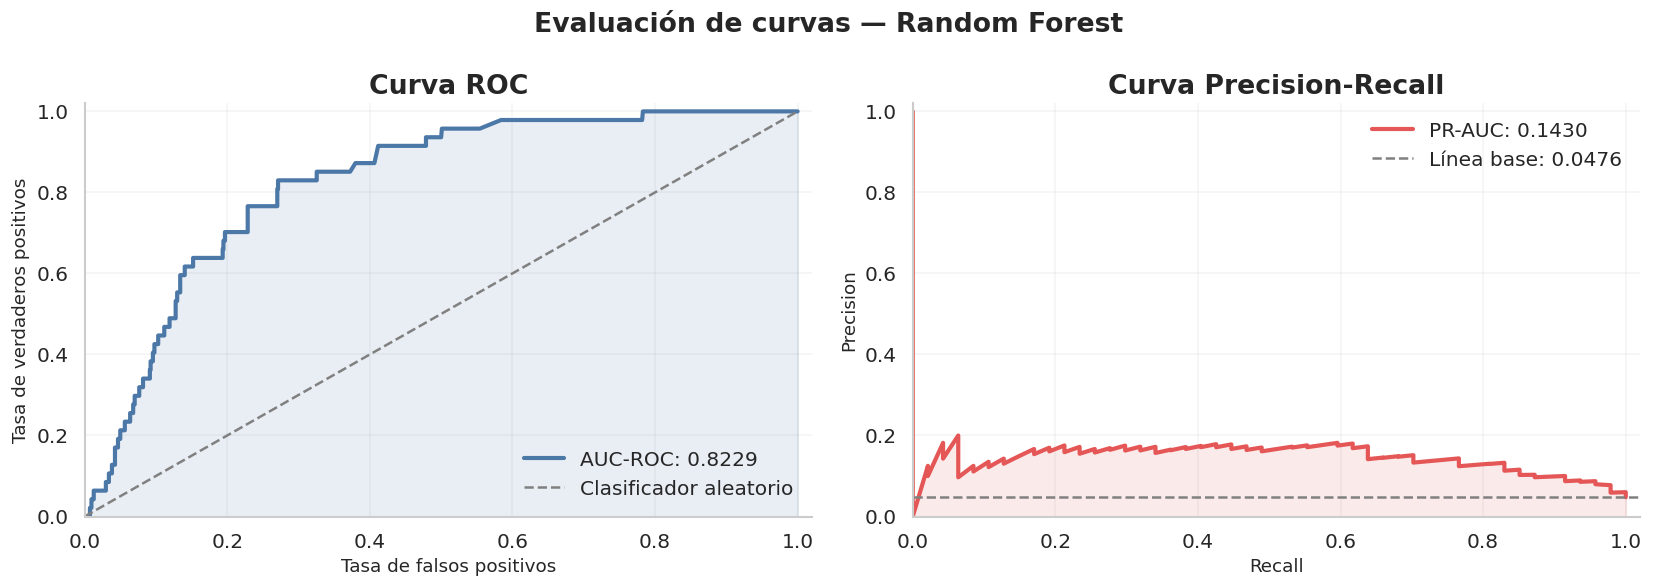

In [70]:
predRandomForest = modeloRandomForest.transform(test)

resultadosRandomForest = evaluar_modelo(
    predRandomForest,
    "Random Forest"
)

graficar_matriz_confusion(
    predRandomForest,
    "Random Forest"
)

graficar_curvas(
    predRandomForest,
    "Random Forest",
    resultadosRandomForest
)


<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">
<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Random Forest</strong>

<p>
El modelo Random Forest presenta un AUC-ROC de 0,8229, lo que indica una buena capacidad discriminativa entre pacientes con y sin derrame cerebral. Asimismo, obtiene un PR-AUC de 0,1430, aproximadamente 3 veces superior a la línea base de 0,0476. Estos resultados sugieren que la combinación de múltiples árboles permite identificar patrones relevantes en los datos.

En cuanto a las métricas de clasificación, el modelo alcanza un Accuracy del 95,24 %, una Precision ponderada del 90,70 % y un F1-Score ponderado del 92,92 %. Sin embargo, todas las observaciones fueron clasificadas como pacientes sin derrame, obteniendo 940 verdaderos negativos y 47 falsos negativos. Lo anterior demuestra que la combinación de múltiples árboles no resulta suficiente por sí sola para contrarrestar el desbalance de clases. En conclusión, Random Forest presenta un buen potencial discriminativo, pero no logra traducir esta capacidad en una identificación efectiva de los pacientes con derrame cerebral bajo la configuración utilizada.
</p>
</div>


### **4.4 - Modelo Gradient-Boosted Trees (GBT)**

Es un algoritmo de aprendizaje por conjuntos basado en la técnica de Boosting, que construye árboles de decisión de manera secuencial. Cada nuevo árbol busca reducir los errores del modelo acumulado.

In [71]:
# Se instancia Modelo
GradientBoosting = GBTClassifier(
    featuresCol="independientes",
    labelCol="Derrame",
    maxIter=50,
    maxDepth=4,
    stepSize=0.1,
    minInstancesPerNode=5,
    subsamplingRate=0.8,
    maxBins=32,
    lossType="logistic",
    seed=42
)


# Se entrena Modelo
modeloGBT = GradientBoosting.fit(train)

Resultados: Gradient-Boosted Trees
----------------------------------------
AUC-ROC: 0.8213
PR-AUC: 0.1419
Accuracy: 0.9453
Precision: 0.9067
Recall: 0.9453
F1-Score: 0.9256


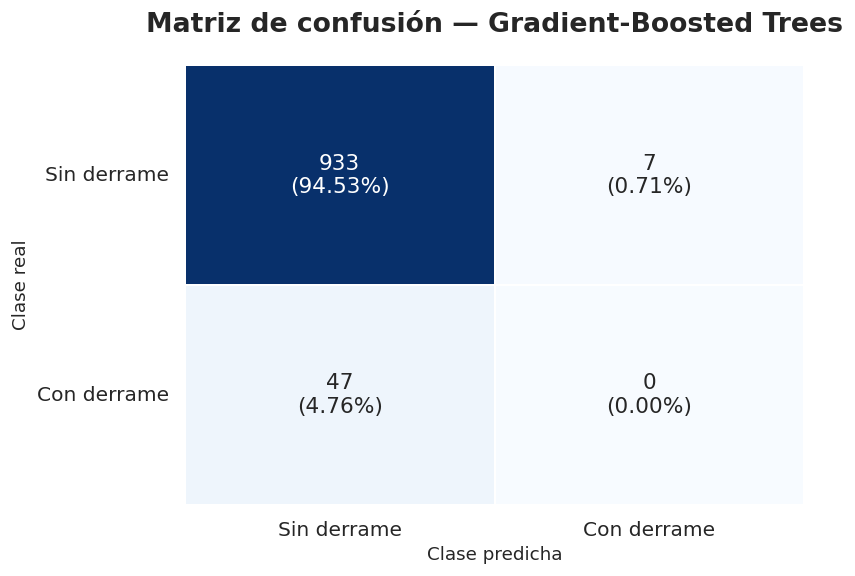

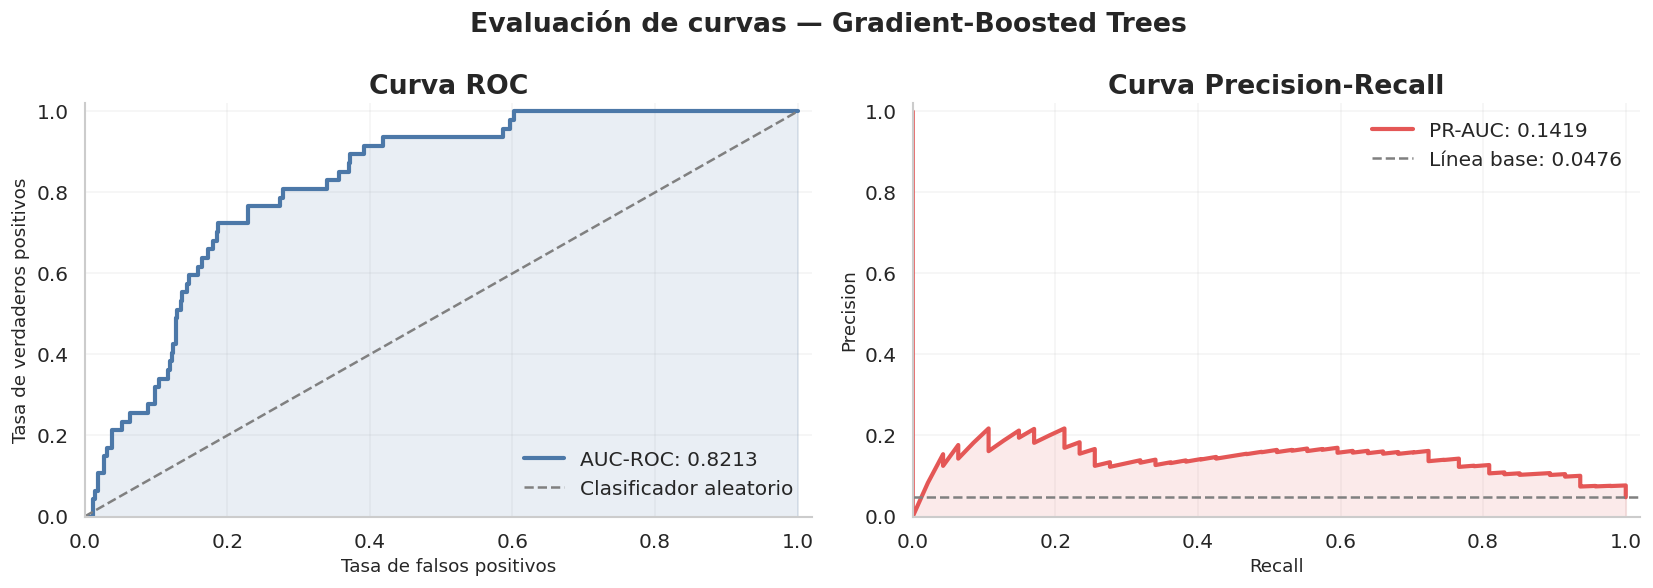

In [72]:
predGBT = modeloGBT.transform(test)

resultadosGBT = evaluar_modelo(
    predGBT,
    "Gradient-Boosted Trees"
)

graficar_matriz_confusion(
    predGBT,
    "Gradient-Boosted Trees"
)

graficar_curvas(
    predGBT,
    "Gradient-Boosted Trees",
    resultadosGBT
)

<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">

<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis Gradient-Boosted Trees</strong>
    
El modelo Gradient-Boosted Trees presenta un AUC-ROC de 0,8213, lo que indica una buena capacidad discriminativa entre pacientes con y sin derrame cerebral. Asimismo, obtiene un PR-AUC de 0,1419, aproximadamente 2,9 superior a la línea base de 0,0476. Estos resultados evidencian que el aprendizaje secuencial de los árboles permite identificar patrones relevantes, aunque persisten dificultades para mantener una precisión elevada en la detección de casos positivos.

Respecto a las métricas de clasificación, el modelo alcanza un Accuracy del 94,53 %, una Precision ponderada del 90,67 % y un F1-Score ponderado del 92,56 %. Si bien el modelo logra identificar un caso positivo, su capacidad de detección sigue siendo insuficiente.En conclusión, Gradient-Boosted Trees demuestra una buena capacidad discriminativa, pero el mecanismo de corrección secuencial de errores no resulta suficiente para superar el desbalance de clases bajo la configuración utilizada.
<p>

</p>
</div>

### **4.5 - Multilayer Perceptron (MLP)**

Es un algoritmo de aprendizaje supervisado basado en redes neuronales artificiales, compuesto por una capa de entrada, una o varias capas ocultas y una capa de salida. Permite capturar relaciones no lineales y complejas entre las características de los pacientes y la variable objetivo.

In [73]:
## Las redes neuronales son sensibles a la escala de variables se requiere estandarizarlas.

scaler = StandardScaler(
    inputCol="independientes",
    outputCol="independientesEscaladas",
    withMean=True,
    withStd=True
)

modeloScaler = scaler.fit(train)

trainMLP = modeloScaler.transform(train)
testMLP = modeloScaler.transform(test)

In [74]:
## Definir tamaño capa de entrada dado el numero de caracteristicas

numCaracteristicas = len(
    trainMLP.select("independientesEscaladas").first()[0]
)

capas = [numCaracteristicas, 16, 8, 2]

print("Arquitectura:", capas)

Arquitectura: [11, 16, 8, 2]


In [75]:
## Se instancia modelo

mlp = MultilayerPerceptronClassifier(
    featuresCol="independientesEscaladas",
    labelCol="Derrame",
    layers=capas,
    maxIter=100,
    blockSize=128,
    solver="l-bfgs",
    seed=42
)


## Se entrena modelo
modeloMLP = mlp.fit(trainMLP)

Resultados: Multilayer Perceptron
----------------------------------------
AUC-ROC: 0.7208
PR-AUC: 0.0936
Accuracy: 0.9382
Precision: 0.9134
Recall: 0.9382
F1-Score: 0.9249


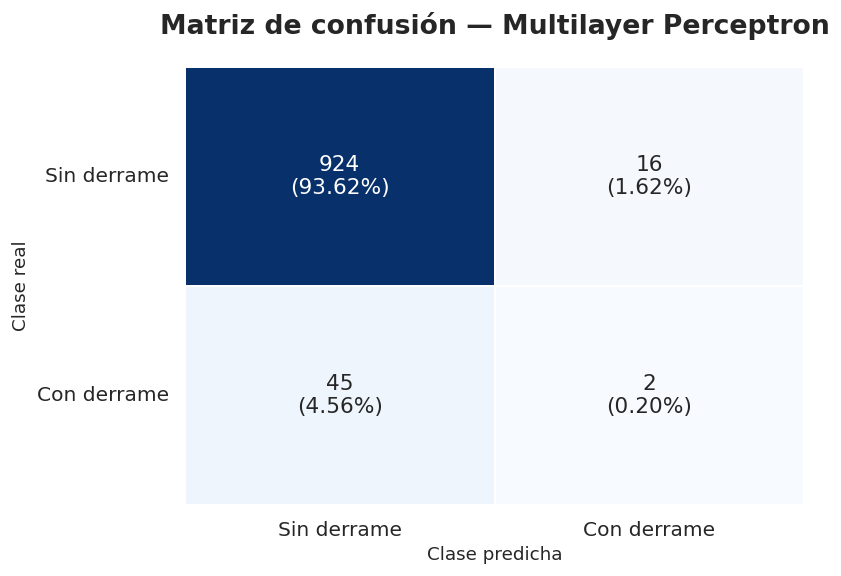

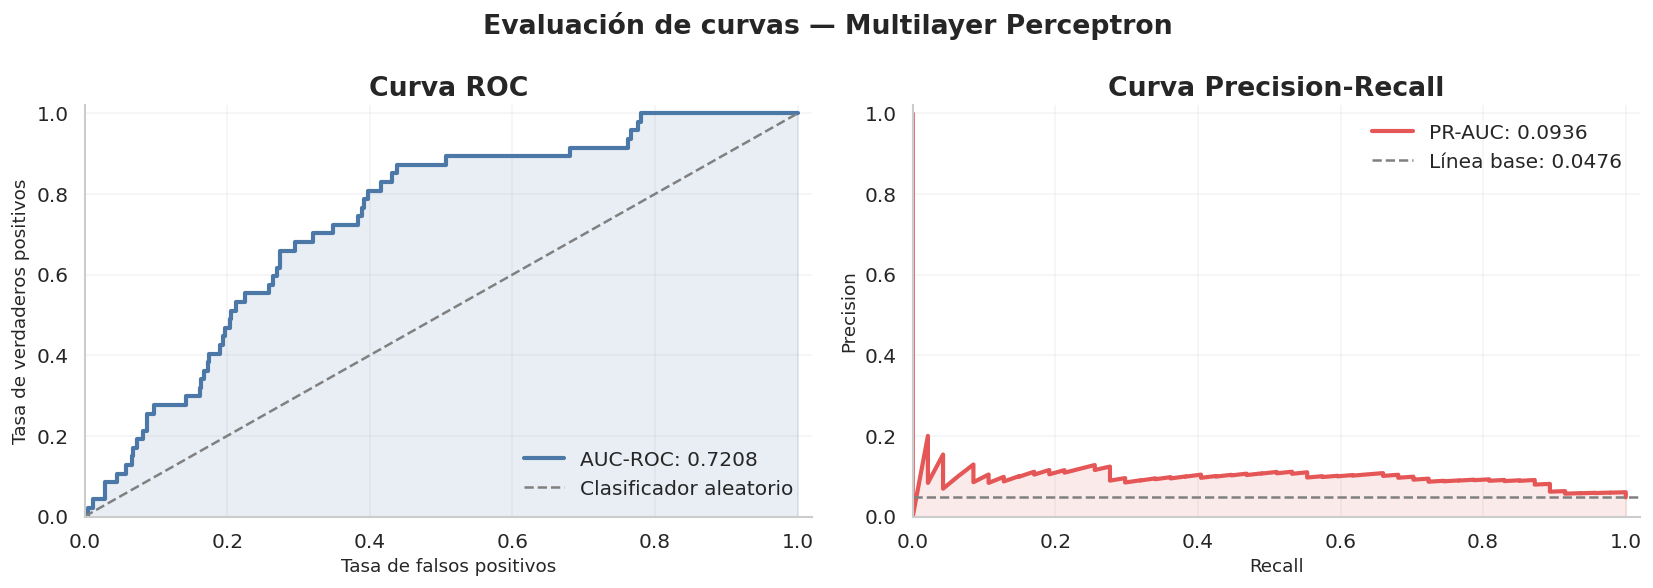

In [77]:
predMLP = modeloMLP.transform(testMLP)


resultadosMLP = evaluar_modelo(
    predMLP,
    "Multilayer Perceptron"
)

graficar_matriz_confusion(
    predMLP,
    "Multilayer Perceptron"
)

graficar_curvas(
    predMLP,
    "Multilayer Perceptron",
    resultadosMLP
)

<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">

<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis MultiLayer Perceptron</strong>
    
El modelo Multilayer Perceptron obtuvo un AUC-ROC de 0,7208, lo que evidencia una capacidad discriminativa moderada entre los pacientes con y sin derrame cerebral. Por su parte, el PR-AUC alcanzó un valor de 0,0936, aproximadamente dos veces superior a la línea base de 0,0476. Sin embargo, la curva Precision-Recall presenta valores de precisión generalmente bajos a lo largo de los diferentes niveles de sensibilidad, evidenciando dificultades para identificar la clase minoritaria sin generar una cantidad considerable de falsos positivos.

Respecto a las métricas generales de clasificación, el modelo alcanzó un Accuracy del 93,82 %, acompañado de una Precision ponderada de 0,9134, un Recall ponderado de 0,9382 y un F1-Score ponderado de 0,9249. No obstante, la matriz de confusión revela que únicamente se identificaron correctamente 2 de los 47 pacientes con derrame cerebral, mientras que los 45 restantes fueron clasificados incorrectamente.

En términos generales, aunque la arquitectura neuronal permite capturar relaciones no lineales entre las características de los pacientes, los resultados obtenidos evidencian que su capacidad de aprendizaje no fue suficiente para superar las dificultades asociadas al desbalance de clases

<p>

</p>
</div>

#### **Se almacenan resultados para analisis general**

In [79]:
resultadosModelos = pd.DataFrame([
    resultadosRLog,
    resultadosArbolDecision,
    resultadosRandomForest,
    resultadosGBT,
    resultadosMLP
])

modelos = {
    "Regresión Logística": modeloRegLog,
    "Decision Tree": modeloArbolDecision,
    "Random Forest": modeloRandomForest,
    "Gradient-Boosted Trees": modeloGBT,
    "Multilayer Perceptron": modeloMLP
}

prediccionesModelos = {
    "Regresión Logística": predRLog,
    "Decision Tree": predArbolDecision,
    "Random Forest": predRandomForest,
    "Gradient-Boosted Trees": predGBT,
    "Multilayer Perceptron": predMLP
}


### **4.6 - Analisis General Modelos**

In [80]:
resultadosComparativos = resultadosModelos.copy()

for nombre, predicciones in prediccionesModelos.items():

    conteos = {
        (int(fila["Derrame"]), int(fila["prediction"])): fila["count"]
        for fila in predicciones
        .groupBy("Derrame", "prediction")
        .count()
        .collect()
    }

    VN = conteos.get((0, 0), 0)
    FP = conteos.get((0, 1), 0)
    FN = conteos.get((1, 0), 0)
    VP = conteos.get((1, 1), 0)


    filtro = resultadosComparativos["Modelo"] == nombre

    resultadosComparativos.loc[filtro, "Verdaderos positivos"] = VP
    resultadosComparativos.loc[filtro, "Verdaderos negativos"] = VN
    resultadosComparativos.loc[filtro, "Falsos positivos"] = FP
    resultadosComparativos.loc[filtro, "Falsos negativos"] = FN


columnasConteos = [
    "Verdaderos positivos",
    "Verdaderos negativos",
    "Falsos positivos",
    "Falsos negativos"
]

resultadosComparativos[columnasConteos] = (
    resultadosComparativos[columnasConteos].astype(int)
)

tablaComparativa = resultadosComparativos.set_index("Modelo").T

metricasMaximizar = [
    "AUC-ROC",
    "PR-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Verdaderos positivos",
    "Verdaderos negativos"
]

metricasMinimizar = [
    "Falsos positivos",
    "Falsos negativos"
]

def resaltar_resultados(fila):

    if fila.max() == fila.min():
        return [""] * len(fila)

    if fila.name in metricasMaximizar:
        mejor = fila.max()
        peor = fila.min()
    elif fila.name in metricasMinimizar:
        mejor = fila.min()
        peor = fila.max()
    else:
        return [""] * len(fila)

    return [
        "background-color: #DCFCE7; color: #166534; font-weight: bold"
        if valor == mejor else
        "background-color: #FEE2E2; color: #991B1B"
        if valor == peor else ""
        for valor in fila
    ]

tablaEstilizada = (
    tablaComparativa.style
    .apply(resaltar_resultados, axis=1)
    .format("{:.4f}")
    .format("{:.0f}", subset=pd.IndexSlice[columnasConteos, :])
    .set_caption("Comparación del rendimiento de los modelos")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px"
    })
)

display(tablaEstilizada)

Modelo,Regresión Logística,Decision Tree,Random Forest,Gradient-Boosted Trees,Multilayer Perceptron
AUC-ROC,0.8187,0.7005,0.8229,0.8213,0.7208
PR-AUC,0.1410,0.1289,0.1430,0.1419,0.0936
Accuracy,0.9524,0.9473,0.9524,0.9453,0.9382
Precision,0.9070,0.9068,0.9070,0.9067,0.9134
Recall,0.9524,0.9473,0.9524,0.9453,0.9382
F1-Score,0.9292,0.9266,0.9292,0.9256,0.9249
Verdaderos positivos,0,0,0,0,2
Verdaderos negativos,940,935,940,933,924
Falsos positivos,0,5,0,7,16
Falsos negativos,47,47,47,47,45


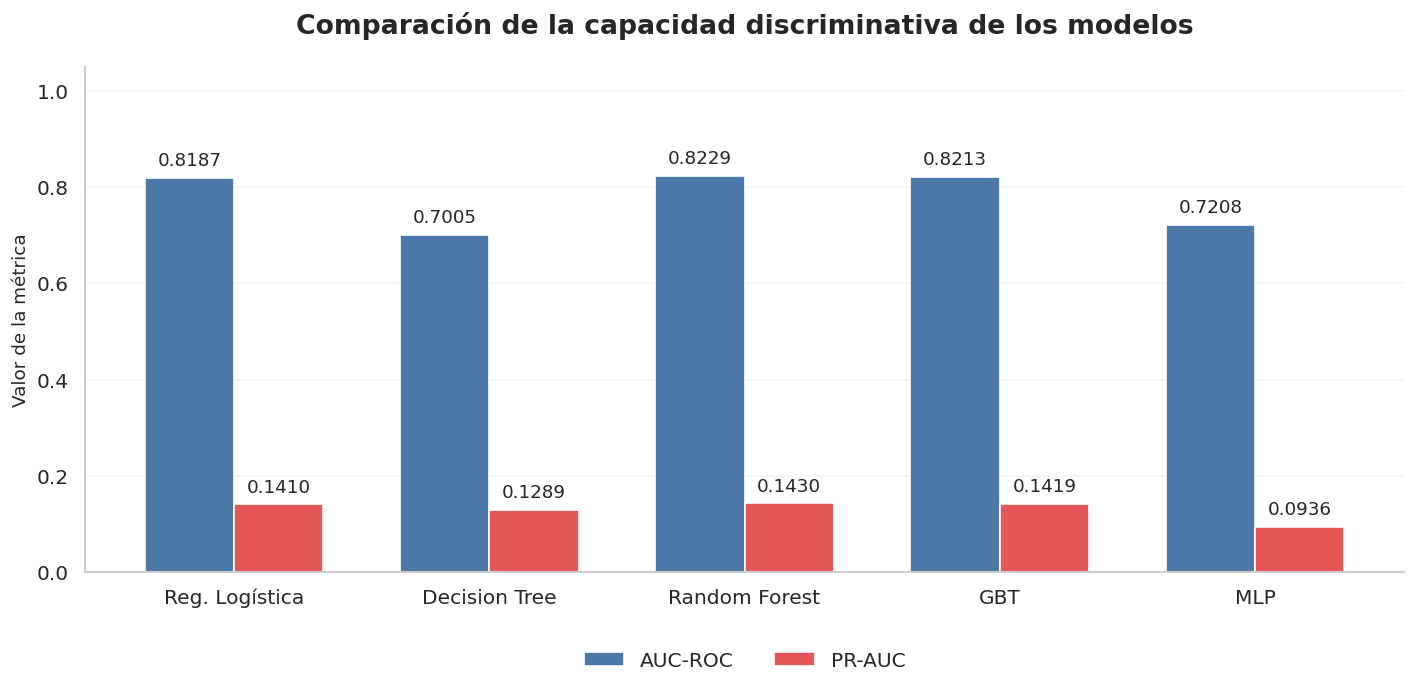

In [82]:

nombresCortos = {
    "Regresión Logística": "Reg. Logística",
    "Decision Tree": "Decision Tree",
    "Random Forest": "Random Forest",
    "Gradient-Boosted Trees": "GBT",
    "Multilayer Perceptron": "MLP"
    
}
fig, ax = plt.subplots(figsize=(12, 6))

posiciones = np.arange(len(resultadosComparativos))
ancho = 0.35

barrasROC = ax.bar(
    posiciones - ancho / 2,
    resultadosComparativos["AUC-ROC"],
    width=ancho,
    color="#4C78A8",
    label="AUC-ROC"
)

barrasPR = ax.bar(
    posiciones + ancho / 2,
    resultadosComparativos["PR-AUC"],
    width=ancho,
    color="#E45756",
    label="PR-AUC"
)

ax.bar_label(
    barrasROC,
    fmt="%.4f",
    padding=5,
    fontsize=11
)

ax.bar_label(
    barrasPR,
    fmt="%.4f",
    padding=5,
    fontsize=11
)

ax.set_xticks(posiciones)

ax.set_xticklabels([
    nombresCortos[nombre]
    for nombre in resultadosComparativos["Modelo"]
])

ax.set_title(
    "Comparación de la capacidad discriminativa de los modelos",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1.05)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

<div style="
    border-left: 5px solid #2E7D32;
    padding: 14px 18px;
    margin: 20px 0;
    border-radius: 6px;
">

<p style="
    font-size: 1.30em;
    font-weight: 700;
    margin: 0 0 8px 0;
">
<strong>Analisis General Modelos</strong>
    
En términos de capacidad discriminativa, Random Forest obtiene los mayores valores de AUC-ROC (0,8229) y PR-AUC (0,1430), seguido de cerca por Gradient-Boosted Trees y Regresión Logística. Por su parte, Decision Tree presenta el menor AUC-ROC (0,7005), mientras que Multilayer Perceptron obtiene el menor PR-AUC (0,0936).

A pesar de que todos los modelos alcanzan una exactitud superior al 93 % y métricas ponderadas superiores al 90 %, ninguno logra identificar satisfactoriamente la clase minoritaria. Únicamente Multilayer Perceptron identifica correctamente 2 de los 47 pacientes con derrame cerebral presentes en el conjunto de prueba, generando 16 falsos positivos. Esto evidencia las dificultades asociadas al desbalance de clases y a la configuración del proceso de clasificación.

Considerando los resultados obtenidos, Random Forest se posiciona como el candidato más prometedor para una posterior optimización, debido a su desempeño en AUC-ROC y PR-AUC. No obstante, Gradient-Boosted Trees y Regresión Logística constituyen alternativas competitivas debido a la cercanía de sus resultados, destacándose esta última por su menor complejidad e interpretabilidad. Sin embargo, bajo la configuración actual, ninguno de los cinco modelos presenta un rendimiento satisfactorio frente al objetivo principal del taller.
<p>

</p>
</div>

## **Conclusiones**

<div style="padding: 10px 15px; border-left: 3px solid #555;">
El análisis exploratorio de los datos permitió identificar caracteristicas asociadas a los derrames cerebrales, siendo las mas importantes la edad y el nivel promedio de glucosa. Por su parte, el índice de masa corporal presentó una menor capacidad para diferenciar las clases. Adicionalmente, se encontro un marcado desbalance en la variable objetivo, puesto que únicamente el 4,87 % de los pacientes registrados presentó un derrame cerebral.
    
La implementación y evaluación de cinco modelos de aprendizaje automático mediante Spark MLlib permitió comparar diferentes enfoques de clasificación, incluyendo modelos lineales, árboles de decisión, técnicas de aprendizaje por conjuntos y redes neuronales artificiales. Random Forest obtuvo los mejores resultados en AUC-ROC (0,8229) y PR-AUC (0,1430), mientras que Multilayer Perceptron fue el único modelo capaz de identificar casos positivos. Sin embargo, ningún modelo logró detectar satisfactoriamente a los pacientes con derrame cerebral. Estos resultados evidencian que las métricas ponderadas son insuficientes para evaluar problemas de clasificación con un elevado desbalance de clases.

Como principal trabajo a futuro, se deberían evaluar estrategias de balanceo de los datos de entrenamiento y optimización de hiperparámetros priorizando la detección de casos positivos. Asimismo, resulta pertinente profundizar en la preparación de los datos, el tratamiento de valores atípicos y la validación de las características generadas, como <code>AltoRiesgo</code>. Finalmente, los modelos desarrollados aún no presentan un desempeño suficiente para su utilización en un contexto clínico, donde las consecuencias de los falsos negativos son especialmente relevantes.

</div>

In [ ]:
sparkRamirez.stop()